# Manuscript evidence pack — v7

Dependency-free table export: LaTeX tables are generated without Jinja2 or optional pandas rendering packages.


## 1. Configuration and input discovery

The output directory is version-specific so obsolete plots from earlier notebook versions are not mixed with manuscript artifacts.


In [1]:

from pathlib import Path
import re
import shutil
import warnings
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

# ------------------------------------------------------------------
# Manuscript-facing configuration
# ------------------------------------------------------------------
SCORED_DATASETS = ["mmlu", "gsm8k", "hellaswag"]
ALL_WORKLOADS = ["mmlu", "gsm8k", "hellaswag", "dolly"]
DATASET_DISPLAY = {
    "mmlu": "MMLU",
    "gsm8k": "GSM8K",
    "hellaswag": "HellaSwag",
    "dolly": "Dolly",
}
CONTEXT_ORDER = ["edge", "local_cpu", "gpu_server"]
CONTEXT_DISPLAY = {
    "edge": "Edge",
    "local_cpu": "Local CPU",
    "gpu_server": "GPU server",
}
PLATFORM_TO_CONTEXT = {
    "pi5": "edge",
    "cpu": "local_cpu",
    "vllm": "gpu_server",
}
PLATFORM_ALIASES = {
    "gpu": "vllm",
    "gpu_vllm": "vllm",
    "cuda": "vllm",
    "raspberry_pi_5": "pi5",
    "raspberrypi5": "pi5",
    "raspberry_pi": "pi5",
    "local_cpu": "cpu",
}
ACCURACY_RETENTION_THRESHOLD = 0.95
COMPACT_TOTAL_PARAMETER_THRESHOLD_B = 7.0
SAVE_DPI = 300
OUTPUT_SUBDIR = Path("results") / "manuscript_evidence_pack_v6"
CLEAN_OUTPUT_ON_RUN = True

cwd = Path.cwd().resolve()

def find_project_root(start: Path) -> Path:
    for candidate in [start] + list(start.parents):
        if (candidate / "results").exists():
            return candidate
    return start.parents[0] if start.name == "notebooks" else start

ROOT = find_project_root(cwd)
CANDIDATE_DIRS = [
    ROOT / "results" / "report_grade_visualizations",
    ROOT / "results",
    ROOT / "notebooks",
    ROOT,
    cwd,
    Path("/mnt/data"),
]

def find_file(filename: str) -> Path:
    for directory in CANDIDATE_DIRS:
        candidate = directory / filename
        if candidate.exists():
            return candidate
    for search_root in [ROOT / "results", ROOT]:
        if search_root.exists():
            matches = sorted(search_root.rglob(filename))
            if matches:
                return matches[0]
    raise FileNotFoundError(
        f"Could not find {filename}. Run the report-grade notebook first, "
        "or place the CSV next to this notebook."
    )

SUMMARY_PATH = find_file("normalized_summary_all.csv")
OUTPUT_DIR = ROOT / OUTPUT_SUBDIR
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
TEXT_DIR = OUTPUT_DIR / "text"
CHECK_DIR = OUTPUT_DIR / "checks"

if CLEAN_OUTPUT_ON_RUN and OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for directory in [FIGURE_DIR, TABLE_DIR, TEXT_DIR, CHECK_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

summary_raw = pd.read_csv(SUMMARY_PATH)

print("Source:", SUMMARY_PATH)
print("Output:", OUTPUT_DIR)
print("Rows:", len(summary_raw))
print("Columns:", sorted(summary_raw.columns))


Source: /home/stephane/resource-efficiency-benchmark/notebooks/results/report_grade_visualizations/normalized_summary_all.csv
Output: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6
Rows: 119
Columns: ['accuracy', 'accuracy_per_1k_ms', 'accuracy_per_joule', 'accuracy_per_second', 'accuracy_sd', 'cpu_percent_avg', 'cpu_percent_avg_sd', 'cpu_percent_peak', 'dataset', 'energy_j', 'energy_per_token_j', 'gpu_util_percent_avg', 'gpu_util_percent_avg_sd', 'gpu_util_percent_peak', 'has_accuracy', 'latency_ms', 'latency_ms_sd', 'model', 'model_alias_dir', 'model_dir', 'model_display', 'model_family', 'model_family_prefix', 'model_family_rank', 'model_id_norm', 'model_label', 'platform', 'platform_display', 'platform_model', 'platform_model_display', 'power_w_avg', 'power_w_avg_sd', 'power_w_peak', 'process_ram_mb_peak', 'ram_used_mb_peak', 'repo_id', 'run_dir', 'run_id', 'samples_per_sec', 'samples_per_sec_sd', 'source_file', 'sustained_tokens_per_sec'

In [2]:
print('LaTeX and Markdown table export is dependency-free; Jinja2 is not required.')


LaTeX and Markdown table export is dependency-free; Jinja2 is not required.


## 2. Canonical model metadata

Filename parsing is used only as a fallback. The explicit registry prevents version numbers such as `qwen2_5_1_5b` from being misread as 5B, and distinguishes **total** from **active** parameters for mixture-of-experts models.


In [3]:

def canonical_token(value) -> str:
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


MODEL_REGISTRY = [
    {
        "display_name": "Llama 3.2 1B (Q8)",
        "aliases": ["Llama-3.2-1B-Instruct-Q8_0.gguf"],
        "family": "Llama 3.2",
        "total_parameters_b": 1.0,
        "active_parameters_b": 1.0,
        "architecture": "dense",
        "precision": "Q8_0",
    },
    {
        "display_name": "Llama 3.2 1B (Q4)",
        "aliases": ["llama-3.2-1b-instruct-q4_k_m.gguf"],
        "family": "Llama 3.2",
        "total_parameters_b": 1.0,
        "active_parameters_b": 1.0,
        "architecture": "dense",
        "precision": "Q4_K_M",
    },
    {
        "display_name": "Llama 3.2 1B (bf16)",
        "aliases": ["llama3_2_1b_bf16"],
        "family": "Llama 3.2",
        "total_parameters_b": 1.0,
        "active_parameters_b": 1.0,
        "architecture": "dense",
        "precision": "bf16",
    },
    {
        "display_name": "Gemma 3 1B (Q8)",
        "aliases": ["gemma-3-1b-it-Q8_0.gguf"],
        "family": "Gemma 3",
        "total_parameters_b": 1.0,
        "active_parameters_b": 1.0,
        "architecture": "dense",
        "precision": "Q8_0",
    },
    {
        "display_name": "Qwen 2.5 1.5B (bf16)",
        "aliases": ["qwen2_5_1_5b_bf16"],
        "family": "Qwen 2.5",
        "total_parameters_b": 1.54,
        "active_parameters_b": 1.54,
        "architecture": "dense",
        "precision": "bf16",
    },
    {
        "display_name": "SmolLM3 3B (Q4)",
        "aliases": ["SmolLM3-3B-Q4_K_M.gguf"],
        "family": "SmolLM3",
        "total_parameters_b": 3.0,
        "active_parameters_b": 3.0,
        "architecture": "dense",
        "precision": "Q4_K_M",
    },
    {
        "display_name": "Ministral 3 3B (Q4)",
        "aliases": ["Ministral-3-3B-Instruct-2512-Q4_K_M.gguf"],
        "family": "Ministral 3",
        "total_parameters_b": 3.0,
        "active_parameters_b": 3.0,
        "architecture": "dense",
        "precision": "Q4_K_M",
    },
    {
        "display_name": "Ministral 3 3B (AWQ)",
        "aliases": ["ministral3_3b_awq"],
        "family": "Ministral 3",
        "total_parameters_b": 3.0,
        "active_parameters_b": 3.0,
        "architecture": "dense",
        "precision": "AWQ",
    },
    {
        "display_name": "Phi-4 Mini 3.8B (Q4)",
        "aliases": ["Phi-4-mini-instruct-Q4_K_M.gguf"],
        "family": "Phi-4 Mini",
        "total_parameters_b": 3.8,
        "active_parameters_b": 3.8,
        "architecture": "dense",
        "precision": "Q4_K_M",
    },
    {
        "display_name": "Phi-4 Mini 3.8B (bf16)",
        "aliases": ["phi4mini_bf16"],
        "family": "Phi-4 Mini",
        "total_parameters_b": 3.8,
        "active_parameters_b": 3.8,
        "architecture": "dense",
        "precision": "bf16",
    },
    {
        "display_name": "Phi-4 Mini 3.8B (GPTQ-4)",
        "aliases": ["phi4mini_gptq_4bit"],
        "family": "Phi-4 Mini",
        "total_parameters_b": 3.8,
        "active_parameters_b": 3.8,
        "architecture": "dense",
        "precision": "GPTQ-4",
    },
    {
        "display_name": "Qwen 3 4B (AWQ)",
        "aliases": ["qwen3_4b_awq"],
        "family": "Qwen 3",
        "total_parameters_b": 4.0,
        "active_parameters_b": 4.0,
        "architecture": "dense",
        "precision": "AWQ",
    },
    {
        "display_name": "Granite 4 H-Tiny (bf16)",
        "aliases": ["granite4_htiny_bf16"],
        "family": "Granite 4",
        "total_parameters_b": 7.0,
        "active_parameters_b": 1.0,
        "architecture": "moe",
        "precision": "bf16",
    },
    {
        "display_name": "Qwen 2.5 7B (AWQ)",
        "aliases": ["qwen2_5_7b_awq"],
        "family": "Qwen 2.5",
        "total_parameters_b": 7.62,
        "active_parameters_b": 7.62,
        "architecture": "dense",
        "precision": "AWQ",
    },
    {
        "display_name": "Ministral 3 8B (AWQ)",
        "aliases": ["ministral3_8b_awq"],
        "family": "Ministral 3",
        "total_parameters_b": 8.0,
        "active_parameters_b": 8.0,
        "architecture": "dense",
        "precision": "AWQ",
    },
    {
        "display_name": "Ministral 3 14B",
        "aliases": ["ministral3_14b"],
        "family": "Ministral 3",
        "total_parameters_b": 14.0,
        "active_parameters_b": 14.0,
        "architecture": "dense",
        "precision": "unspecified",
    },
    {
        "display_name": "Phi-4 14B (bf16)",
        "aliases": ["phi4_14b_bf16"],
        "family": "Phi-4",
        "total_parameters_b": 14.0,
        "active_parameters_b": 14.0,
        "architecture": "dense",
        "precision": "bf16",
    },
    {
        "display_name": "Qwen 3 30B-A3B (bf16)",
        "aliases": ["qwen3_30b_instruct_bf16"],
        "family": "Qwen 3",
        "total_parameters_b": 30.5,
        "active_parameters_b": 3.3,
        "architecture": "moe",
        "precision": "bf16",
    },
    {
        "display_name": "Kimi Linear 48B-A3B (bf16)",
        "aliases": ["kimi_linear_48b_bf16"],
        "family": "Kimi Linear",
        "total_parameters_b": 48.0,
        "active_parameters_b": 3.0,
        "architecture": "moe",
        "precision": "bf16",
    },
    {
        "display_name": "Llama 3.3 70B (FP8)",
        "aliases": ["llama3_3_70b_fp8"],
        "family": "Llama 3.3",
        "total_parameters_b": 70.0,
        "active_parameters_b": 70.0,
        "architecture": "dense",
        "precision": "FP8",
    },
    {
        "display_name": "Apertus 70B (bf16)",
        "aliases": ["apertus_70b_instruct_bf16"],
        "family": "Apertus",
        "total_parameters_b": 70.0,
        "active_parameters_b": 70.0,
        "architecture": "dense",
        "precision": "bf16",
    },
]

ALIAS_TO_METADATA = {}
for record in MODEL_REGISTRY:
    for alias in record["aliases"]:
        ALIAS_TO_METADATA[canonical_token(alias)] = record


def fallback_parameter_count(model_name: str) -> float:
    """Fallback only; explicit registry values take precedence."""
    text = str(model_name).lower().replace("_", "-")
    moe = re.search(r"(?:^|[^0-9])(\d+)\s*[x×]\s*(\d+(?:\.\d+)?)\s*b(?:[^a-z]|$)", text)
    if moe:
        return float(moe.group(1)) * float(moe.group(2))
    matches = re.findall(r"(?:^|[^0-9])(\d+(?:\.\d+)?)\s*b(?:[^a-z]|$)", text)
    return max(map(float, matches)) if matches else np.nan


def resolve_metadata(row: pd.Series) -> pd.Series:
    candidate_fields = [
        "model_id_norm", "model", "model_label", "model_display", "repo_id"
    ]
    record = None
    matched_value = None
    for field in candidate_fields:
        if field in row.index and pd.notna(row[field]):
            key = canonical_token(row[field])
            if key in ALIAS_TO_METADATA:
                record = ALIAS_TO_METADATA[key]
                matched_value = row[field]
                break

    if record is None:
        inferred = fallback_parameter_count(row.get("model", ""))
        return pd.Series({
            "model_display_canonical": str(row.get("model_display", row.get("model", "unknown"))),
            "model_family_canonical": str(row.get("model_family", "unknown")),
            "total_parameters_b": inferred,
            "active_parameters_b": inferred,
            "architecture": "unknown",
            "precision": "unknown",
            "metadata_source": "filename fallback",
            "metadata_match": np.nan,
        })

    return pd.Series({
        "model_display_canonical": record["display_name"],
        "model_family_canonical": record["family"],
        "total_parameters_b": record["total_parameters_b"],
        "active_parameters_b": record["active_parameters_b"],
        "architecture": record["architecture"],
        "precision": record["precision"],
        "metadata_source": "explicit registry",
        "metadata_match": matched_value,
    })


def normalize_platform(value) -> str:
    token = str(value).strip().lower().replace("-", "_").replace(" ", "_")
    return PLATFORM_ALIASES.get(token, token)


def normalize_dataset(value) -> str:
    token = re.sub(r"[^a-z0-9]+", "", str(value).lower())
    aliases = {
        "mmlu": "mmlu",
        "mmlutest": "mmlu",
        "gsm8k": "gsm8k",
        "gsm8ktest": "gsm8k",
        "hellaswag": "hellaswag",
        "hellaswagtest": "hellaswag",
        "dolly": "dolly",
        "databricksdolly15k": "dolly",
    }
    return aliases.get(token, token)


summary = summary_raw.copy()
required = {"dataset", "platform", "model"}
missing = sorted(required - set(summary.columns))
if missing:
    raise KeyError(
        f"normalized_summary_all.csv is missing required columns {missing}. "
        f"Available columns: {sorted(summary.columns)}"
    )

summary["dataset"] = summary["dataset"].map(normalize_dataset)
summary["platform"] = summary["platform"].map(normalize_platform)
summary["context"] = summary["platform"].map(PLATFORM_TO_CONTEXT)
summary["context_display"] = summary["context"].map(CONTEXT_DISPLAY)
summary["model"] = summary["model"].astype(str)

metadata = summary.apply(resolve_metadata, axis=1)
summary = pd.concat([summary, metadata], axis=1)
summary["compact_total"] = summary["total_parameters_b"].le(COMPACT_TOTAL_PARAMETER_THRESHOLD_B)

metadata_audit = (
    summary[
        [
            "model", "model_display_canonical", "model_family_canonical",
            "total_parameters_b", "active_parameters_b", "architecture",
            "precision", "metadata_source", "metadata_match",
        ]
    ]
    .drop_duplicates()
    .sort_values(["total_parameters_b", "model"], na_position="last")
)

metadata_audit.to_csv(CHECK_DIR / "model_metadata_audit.csv", index=False)
display(metadata_audit)

unknown_metadata = metadata_audit[
    metadata_audit["metadata_source"].ne("explicit registry")
]
if not unknown_metadata.empty:
    print("WARNING: models using fallback metadata:")
    display(unknown_metadata)


,model,model_display_canonical,model_family_canonical,total_parameters_b,active_parameters_b,architecture,precision,metadata_source,metadata_match
0,Llama-3.2-1B-Instruct-Q8_0.gguf,Llama 3.2 1B (Q8),Llama 3.2,1.00,1.00,dense,Q8_0,explicit registry,Llama-3.2-1B-Instruct-Q8_0.gguf
21,gemma-3-1b-it-Q8_0.gguf,Gemma 3 1B (Q8),Gemma 3,1.00,1.00,dense,Q8_0,explicit registry,gemma-3-1b-it-Q8_0.gguf
47,llama-3.2-1b-instruct-q4_k_m.gguf,Llama 3.2 1B (Q4),Llama 3.2,1.00,1.00,dense,Q4_K_M,explicit registry,llama-3.2-1b-instruct-q4_k_m.gguf
68,llama3_2_1b_bf16,Llama 3.2 1B (bf16),Llama 3.2,1.00,1.00,dense,bf16,explicit registry,llama3_2_1b_bf16
103,qwen2_5_1_5b_bf16,Qwen 2.5 1.5B (bf16),Qwen 2.5,1.54,1.54,dense,bf16,explicit registry,qwen2_5_1_5b_bf16
4,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,Ministral 3 3B (Q4),Ministral 3,3.00,3.00,dense,Q4_K_M,explicit registry,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf
35,SmolLM3-3B-Q4_K_M.gguf,SmolLM3 3B (Q4),SmolLM3,3.00,3.00,dense,Q4_K_M,explicit registry,SmolLM3-3B-Q4_K_M.gguf
83,ministral3_3b_awq,Ministral 3 3B (AWQ),Ministral 3,3.00,3.00,dense,AWQ,explicit registry,ministral3_3b_awq
12,Phi-4-mini-instruct-Q4_K_M.gguf,Phi-4 Mini 3.8B (Q4),Phi-4 Mini,3.80,3.80,dense,Q4_K_M,explicit registry,Phi-4-mini-instruct-Q4_K_M.gguf
95,phi4mini_bf16,Phi-4 Mini 3.8B (bf16),Phi-4 Mini,3.80,3.80,dense,bf16,explicit registry,phi4mini_bf16


## 3. Normalize metrics and construct context-aware summaries

For GPU, deployment memory means peak VRAM. For edge and local CPU, it means peak system RAM. These values are never pooled into a single unqualified “RAM” axis.


In [4]:

NUMERIC_CANDIDATES = [
    "accuracy", "accuracy_sd",
    "latency_ms", "latency_ms_sd",
    "ttft_ms", "ttft_ms_sd",
    "tokens_per_sec", "tokens_per_sec_sd",
    "sustained_tokens_per_sec", "sustained_tokens_per_sec_sd",
    "samples_per_sec", "samples_per_sec_sd",
    "ram_used_mb_peak", "process_ram_mb_peak",
    "vram_used_mb_peak",
    "cpu_percent_avg", "cpu_percent_peak",
    "gpu_util_percent_avg", "gpu_util_percent_peak",
    "temperature_c_avg", "temperature_c_peak",
    "power_w_avg", "power_w_peak",
    "energy_j", "energy_per_token_j",
]
NUMERIC_METRICS = [c for c in NUMERIC_CANDIDATES if c in summary.columns]
for column in NUMERIC_METRICS:
    summary[column] = pd.to_numeric(summary[column], errors="coerce")

if "energy_j" not in summary.columns and {"power_w_avg", "latency_ms"}.issubset(summary.columns):
    summary["energy_j"] = summary["power_w_avg"] * summary["latency_ms"] / 1000.0
    NUMERIC_METRICS.append("energy_j")

IDENTITY = [
    "dataset", "platform", "context", "context_display", "model",
    "model_display_canonical", "model_family_canonical",
    "total_parameters_b", "active_parameters_b", "architecture", "precision",
    "compact_total",
]

agg = (
    summary.groupby(IDENTITY, dropna=False, as_index=False)[NUMERIC_METRICS]
    .mean(numeric_only=True)
)

agg["latency_s"] = agg["latency_ms"] / 1000.0 if "latency_ms" in agg else np.nan
agg["ttft_s"] = agg["ttft_ms"] / 1000.0 if "ttft_ms" in agg else np.nan

agg["deployment_memory_mb"] = np.where(
    agg["context"].eq("gpu_server"),
    agg.get("vram_used_mb_peak", np.nan),
    agg.get("ram_used_mb_peak", np.nan),
)
agg["deployment_memory_gib"] = agg["deployment_memory_mb"] / 1024.0
agg["deployment_memory_type"] = np.where(
    agg["context"].eq("gpu_server"), "VRAM", "system RAM"
)

# A clearly defined short-output cost-effectiveness indicator.
# It estimates expected correct responses per second under sequential requests.
if "samples_per_sec" in agg.columns:
    agg["expected_correct_per_second"] = agg["accuracy"] * agg["samples_per_sec"]
else:
    agg["expected_correct_per_second"] = agg["accuracy"] / agg["latency_s"]

# Latency-derived version retained for audit.
agg["accuracy_over_latency_s"] = agg["accuracy"] / agg["latency_s"]

print("Datasets:", sorted(agg["dataset"].dropna().unique()))
print("Contexts:", sorted(agg["context"].dropna().unique()))
print("Rows after aggregation:", len(agg))
display(agg.head())


Datasets: ['dolly', 'gsm8k', 'hellaswag', 'mmlu']
Contexts: ['edge', 'gpu_server', 'local_cpu']
Rows after aggregation: 92


,dataset,platform,context,context_display,model,model_display_canonical,model_family_canonical,total_parameters_b,active_parameters_b,architecture,precision,compact_total,accuracy,accuracy_sd,latency_ms,latency_ms_sd,ttft_ms,ttft_ms_sd,tokens_per_sec,tokens_per_sec_sd,sustained_tokens_per_sec,sustained_tokens_per_sec_sd,samples_per_sec,samples_per_sec_sd,ram_used_mb_peak,process_ram_mb_peak,vram_used_mb_peak,cpu_percent_avg,cpu_percent_peak,gpu_util_percent_avg,gpu_util_percent_peak,temperature_c_avg,temperature_c_peak,power_w_avg,power_w_peak,energy_j,energy_per_token_j,latency_s,ttft_s,deployment_memory_mb,deployment_memory_gib,deployment_memory_type,expected_correct_per_second,accuracy_over_latency_s
0,dolly,cpu,local_cpu,Local CPU,Llama-3.2-1B-Instruct-Q8_0.gguf,Llama 3.2 1B (Q8),Llama 3.2,1.0,1.0,dense,Q8_0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,system RAM,NaN,NaN
1,dolly,cpu,local_cpu,Local CPU,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,Ministral 3 3B (Q4),Ministral 3,3.0,3.0,dense,Q4_K_M,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,system RAM,NaN,NaN
2,dolly,cpu,local_cpu,Local CPU,Phi-4-mini-instruct-Q4_K_M.gguf,Phi-4 Mini 3.8B (Q4),Phi-4 Mini,3.8,3.8,dense,Q4_K_M,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,system RAM,NaN,NaN
3,dolly,cpu,local_cpu,Local CPU,gemma-3-1b-it-Q8_0.gguf,Gemma 3 1B (Q8),Gemma 3,1.0,1.0,dense,Q8_0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,system RAM,NaN,NaN
4,dolly,pi5,edge,Edge,Phi-4-mini-instruct-Q4_K_M.gguf,Phi-4 Mini 3.8B (Q4),Phi-4 Mini,3.8,3.8,dense,Q4_K_M,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,system RAM,NaN,NaN


## 4. Export and plotting helpers

In [5]:

def latex_escape(value: str) -> str:
    """Escape ordinary text for LaTeX while preserving selected math symbols."""
    text = str(value)

    placeholders = {
        "×": "@@TIMES@@",
        "≤": "@@LEQ@@",
        "≥": "@@GEQ@@",
        "∼": "@@SIM@@",
        "≈": "@@APPROX@@",
        "°": "@@DEGREE@@",
        "→": "@@ARROW@@",
    }
    for symbol, placeholder in placeholders.items():
        text = text.replace(symbol, placeholder)

    text = (
        text.replace("–", "--")
        .replace("—", "---")
        .replace("−", "-")
        .replace("’", "'")
        .replace("“", "``")
        .replace("”", "''")
    )

    text = text.replace("\\", "@@BACKSLASH@@")
    for old, new in [
        ("&", r"\&"),
        ("%", r"\%"),
        ("$", r"\$"),
        ("#", r"\#"),
        ("_", r"\_"),
        ("{", r"\{"),
        ("}", r"\}"),
        ("~", r"\textasciitilde{}"),
        ("^", r"\textasciicircum{}"),
    ]:
        text = text.replace(old, new)

    text = text.replace("@@BACKSLASH@@", r"\textbackslash{}")

    latex_symbols = {
        "@@TIMES@@": r"$\times$",
        "@@LEQ@@": r"$\leq$",
        "@@GEQ@@": r"$\geq$",
        "@@SIM@@": r"$\sim$",
        "@@APPROX@@": r"$\approx$",
        "@@DEGREE@@": r"$^\circ$",
        "@@ARROW@@": r"$\rightarrow$",
    }
    for placeholder, latex in latex_symbols.items():
        text = text.replace(placeholder, latex)

    return text


def normalize_float_format(float_format: str) -> str:
    """Convert a printf-style float format into Python's format syntax."""
    text = str(float_format)
    return text[1:] if text.startswith("%") else text


def format_table_value(
    value,
    float_format: str = ".3f",
    output: str = "latex",
) -> str:
    """Format scalar values consistently for Markdown and LaTeX."""
    if pd.isna(value):
        rendered = "--"
    elif isinstance(value, (bool, np.bool_)):
        rendered = "Yes" if bool(value) else "No"
    elif isinstance(value, (float, np.floating)):
        rendered = format(float(value), normalize_float_format(float_format))
    elif isinstance(value, (int, np.integer)):
        rendered = str(int(value))
    else:
        rendered = str(value)

    return latex_escape(rendered) if output == "latex" else rendered


def markdown_table(
    df: pd.DataFrame,
    float_format: str = ".3f",
) -> str:
    """Render a Markdown table without optional packages."""
    headers = [str(column) for column in df.columns]
    rows = [
        [
            format_table_value(
                value,
                float_format=float_format,
                output="markdown",
            )
            for value in row
        ]
        for row in df.itertuples(index=False, name=None)
    ]

    widths = []
    for index, header in enumerate(headers):
        row_widths = [len(row[index]) for row in rows]
        widths.append(max([len(header)] + row_widths))

    header_line = "| " + " | ".join(
        header.ljust(widths[index])
        for index, header in enumerate(headers)
    ) + " |"
    separator = "|-" + "-|-".join("-" * width for width in widths) + "-|"
    body = [
        "| " + " | ".join(
            value.ljust(widths[index])
            for index, value in enumerate(row)
        ) + " |"
        for row in rows
    ]
    return "\n".join([header_line, separator] + body)


def dataframe_to_latex_string(
    df: pd.DataFrame,
    caption: str,
    label: str,
    float_format: str = ".3f",
    position: str = "t",
) -> str:
    """Render a complete booktabs table using only Python string operations."""
    if len(df.columns) == 0:
        raise ValueError("Cannot export a table with zero columns.")

    column_spec = "".join(
        "r" if pd.api.types.is_numeric_dtype(df[column]) else "l"
        for column in df.columns
    )

    lines = [
        rf"\begin{{table}}[{position}]",
        r"\centering",
        rf"\caption{{{latex_escape(caption)}}}",
        rf"\label{{{latex_escape(label)}}}",
        r"\small",
        rf"\begin{{tabular}}{{{column_spec}}}",
        r"\toprule",
        " & ".join(latex_escape(column) for column in df.columns) + r" \\",
        r"\midrule",
    ]

    for row in df.itertuples(index=False, name=None):
        lines.append(
            " & ".join(
                format_table_value(
                    value,
                    float_format=float_format,
                    output="latex",
                )
                for value in row
            )
            + r" \\"
        )

    lines.extend([
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
        "",
    ])
    return "\n".join(lines)


def export_table(
    df: pd.DataFrame,
    stem: str,
    caption: str,
    label: str,
    float_format: str = "%.3f",
):
    csv_path = TABLE_DIR / f"{stem}.csv"
    md_path = TABLE_DIR / f"{stem}.md"
    tex_path = TABLE_DIR / f"{stem}.tex"

    df.to_csv(csv_path, index=False)

    md_path.write_text(
        f"### {caption}\n\n"
        f"{markdown_table(df, float_format=float_format)}\n",
        encoding="utf-8",
    )

    tex_path.write_text(
        dataframe_to_latex_string(
            df=df,
            caption=caption,
            label=label,
            float_format=float_format,
            position="t",
        ),
        encoding="utf-8",
    )

    return {
        "csv": csv_path,
        "md": md_path,
        "tex": tex_path,
    }


def save_figure(fig, stem: str):
    png = FIGURE_DIR / f"{stem}.png"
    pdf = FIGURE_DIR / f"{stem}.pdf"
    fig.savefig(png, dpi=SAVE_DPI, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    print("saved:", png)
    plt.show()
    return png, pdf


def pareto_mask(
    df: pd.DataFrame,
    x: str,
    y: str,
    maximize_x: bool,
    maximize_y: bool = True,
) -> pd.Series:
    values = df[[x, y]].to_numpy(dtype=float)
    efficient = np.ones(len(df), dtype=bool)
    for i, point in enumerate(values):
        if np.isnan(point).any():
            efficient[i] = False
            continue
        for j, other in enumerate(values):
            if i == j or np.isnan(other).any():
                continue
            x_no_worse = other[0] >= point[0] if maximize_x else other[0] <= point[0]
            y_no_worse = other[1] >= point[1] if maximize_y else other[1] <= point[1]
            x_strict = other[0] > point[0] if maximize_x else other[0] < point[0]
            y_strict = other[1] > point[1] if maximize_y else other[1] < point[1]
            if x_no_worse and y_no_worse and (x_strict or y_strict):
                efficient[i] = False
                break
    return pd.Series(efficient, index=df.index)


def short_name(value: str, max_chars: int = 25) -> str:
    text = str(value)
    for token in [
        " (bf16)", " (Q4_K_M)", " (Q8_0)", " (GPTQ-4)", " (AWQ)",
        "-Instruct", "-instruct", "_instruct", ".gguf",
    ]:
        text = text.replace(token, "")
    return text if len(text) <= max_chars else text[: max_chars - 1] + "…"


CALLOUT_OFFSETS = [
    (10, 12), (10, -16), (-10, 12), (-10, -16),
    (18, 24), (18, -26), (-18, 24), (-18, -26),
]


def annotate_rows(ax, frame, x, y, max_labels=5):
    selected = frame.copy()
    if "pareto" in selected.columns:
        selected = selected[selected["pareto"]]
    selected = selected.sort_values(y, ascending=False).head(max_labels)

    xmid = np.mean(ax.get_xlim())
    for i, (_, row) in enumerate(selected.iterrows()):
        dx, dy = CALLOUT_OFFSETS[i % len(CALLOUT_OFFSETS)]
        if row[x] > xmid:
            dx = -abs(dx)
            ha = "right"
        else:
            dx = abs(dx)
            ha = "left"
        ax.annotate(
            short_name(row["model_display_canonical"]),
            xy=(row[x], row[y]),
            xytext=(dx, dy),
            textcoords="offset points",
            ha=ha,
            va="center",
            fontsize=7.3,
            bbox={"boxstyle": "round,pad=0.16", "facecolor": "white", "alpha": 0.85},
            arrowprops={"arrowstyle": "-", "linewidth": 0.6},
            annotation_clip=False,
        )


def context_subset(context: str, dataset: str | None = None) -> pd.DataFrame:
    frame = agg[agg["context"].eq(context)].copy()
    if dataset is not None:
        frame = frame[frame["dataset"].eq(dataset)].copy()
    return frame


## 5. Static manuscript tables: deployment contexts and hardware

In [6]:

table_01 = pd.DataFrame([
    {
        "Context": "Edge",
        "Hardware envelope": "Raspberry Pi 5; 4 cores; 8 GB RAM; no GPU",
        "Backend": "llama.cpp",
        "Model scale": "up to ≈4B, quantized",
        "Operational objective": "feasibility first, then accuracy",
        "Workload profile": "short interactive requests",
        "Binding constraint": "RAM, then thermal/latency",
    },
    {
        "Context": "Local CPU",
        "Hardware envelope": "Laptop CPU; 12 threads; 30 GB RAM; no discrete GPU",
        "Backend": "llama.cpp (Podman)",
        "Model scale": "≈1B–4B, quantized in current pool",
        "Operational objective": "responsiveness under memory budget",
        "Workload profile": "short-to-mid generation",
        "Binding constraint": "latency",
    },
    {
        "Context": "GPU server",
        "Hardware envelope": "2× RTX PRO 6000 Blackwell; ≈96 GiB VRAM each",
        "Backend": "vLLM",
        "Model scale": "up to ≈70B; bf16/fp8/AWQ/GPTQ",
        "Operational objective": "accuracy and throughput",
        "Workload profile": "mixed, including long generation",
        "Binding constraint": "accuracy–latency/throughput trade-off",
    },
])

export_table(
    table_01,
    "table_01_deployment_contexts",
    "Deployment contexts used to organize the evaluation.",
    "tab:deployment-contexts",
)

table_03 = pd.DataFrame([
    {
        "Platform": "Raspberry Pi 5",
        "CPU": "Cortex-A76, 4 cores",
        "RAM": "7.9 GiB",
        "GPU": "none",
        "VRAM": "—",
        "OS": "Debian 13 (trixie)",
        "Backend": "llama.cpp",
    },
    {
        "Platform": "Laptop CPU",
        "CPU": "Intel i5-1345U, 10c/12t",
        "RAM": "30 GiB",
        "GPU": "integrated Intel",
        "VRAM": "—",
        "OS": "OpenSUSE Tumbleweed",
        "Backend": "llama.cpp (Podman)",
    },
    {
        "Platform": "GPU server",
        "CPU": "2× Xeon 6520P, 96 threads",
        "RAM": "251 GiB",
        "GPU": "2× RTX PRO 6000 Blackwell",
        "VRAM": "97,887 MiB per GPU",
        "OS": "Ubuntu 24.04.3 LTS",
        "Backend": "vLLM 0.20.0",
    },
])

export_table(
    table_03,
    "table_03_hardware_platforms",
    "Hardware platforms used for evaluation.",
    "tab:hardware-platforms",
)

display(table_01)
display(table_03)


,Context,Hardware envelope,Backend,Model scale,Operational objective,Workload profile,Binding constraint
0,Edge,Raspberry Pi 5; 4 cores; 8 GB RAM; no GPU,llama.cpp,"up to ≈4B, quantized","feasibility first, then accuracy",short interactive requests,"RAM, then thermal/latency"
1,Local CPU,Laptop CPU; 12 threads; 30 GB RAM; no discrete GPU,llama.cpp (Podman),"≈1B–4B, quantized in current pool",responsiveness under memory budget,short-to-mid generation,latency
2,GPU server,2× RTX PRO 6000 Blackwell; ≈96 GiB VRAM each,vLLM,up to ≈70B; bf16/fp8/AWQ/GPTQ,accuracy and throughput,"mixed, including long generation",accuracy–latency/throughput trade-off


,Platform,CPU,RAM,GPU,VRAM,OS,Backend
0,Raspberry Pi 5,"Cortex-A76, 4 cores",7.9 GiB,none,—,Debian 13 (trixie),llama.cpp
1,Laptop CPU,"Intel i5-1345U, 10c/12t",30 GiB,integrated Intel,—,OpenSUSE Tumbleweed,llama.cpp (Podman)
2,GPU server,"2× Xeon 6520P, 96 threads",251 GiB,2× RTX PRO 6000 Blackwell,"97,887 MiB per GPU",Ubuntu 24.04.3 LTS,vLLM 0.20.0


## 6. Table 2: evaluated model configurations and metadata

This table is generated from the models actually present in `normalized_summary_all.csv`; the notebook does not hard-code “nineteen” configurations.


In [7]:

table_02 = (
    agg[
        [
            "context_display", "model_display_canonical", "model_family_canonical",
            "total_parameters_b", "active_parameters_b", "architecture", "precision",
        ]
    ]
    .drop_duplicates()
    .rename(columns={
        "context_display": "Context",
        "model_display_canonical": "Model configuration",
        "model_family_canonical": "Family",
        "total_parameters_b": "Total parameters (B)",
        "active_parameters_b": "Active parameters (B)",
        "architecture": "Architecture",
        "precision": "Precision / quantization",
    })
)

table_02["Context order"] = table_02["Context"].map(
    {CONTEXT_DISPLAY[k]: i for i, k in enumerate(CONTEXT_ORDER)}
)
table_02 = (
    table_02.sort_values(
        ["Context order", "Total parameters (B)", "Model configuration"]
    )
    .drop(columns="Context order")
    .reset_index(drop=True)
)

export_table(
    table_02,
    "table_02_evaluated_model_configurations",
    "Evaluated language-model configurations, grouped by deployment context and parameter scale.",
    "tab:evaluated-models",
)

configuration_count = len(table_02)
base_model_count = table_02["Family"].nunique()
print("Evaluated context/model configurations:", configuration_count)
print("Unique model families:", base_model_count)
display(table_02)


Evaluated context/model configurations: 23
Unique model families: 12


,Context,Model configuration,Family,Total parameters (B),Active parameters (B),Architecture,Precision / quantization
0,Edge,Gemma 3 1B (Q8),Gemma 3,1.00,1.00,dense,Q8_0
1,Edge,Llama 3.2 1B (Q4),Llama 3.2,1.00,1.00,dense,Q4_K_M
2,Edge,SmolLM3 3B (Q4),SmolLM3,3.00,3.00,dense,Q4_K_M
3,Edge,Phi-4 Mini 3.8B (Q4),Phi-4 Mini,3.80,3.80,dense,Q4_K_M
4,Local CPU,Gemma 3 1B (Q8),Gemma 3,1.00,1.00,dense,Q8_0
5,Local CPU,Llama 3.2 1B (Q8),Llama 3.2,1.00,1.00,dense,Q8_0
6,Local CPU,Ministral 3 3B (Q4),Ministral 3,3.00,3.00,dense,Q4_K_M
7,Local CPU,Phi-4 Mini 3.8B (Q4),Phi-4 Mini,3.80,3.80,dense,Q4_K_M
8,GPU server,Llama 3.2 1B (bf16),Llama 3.2,1.00,1.00,dense,bf16
9,GPU server,Qwen 2.5 1.5B (bf16),Qwen 2.5,1.54,1.54,dense,bf16


## 7. Figure 1: benchmarking framework architecture

saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_01_framework_architecture.png


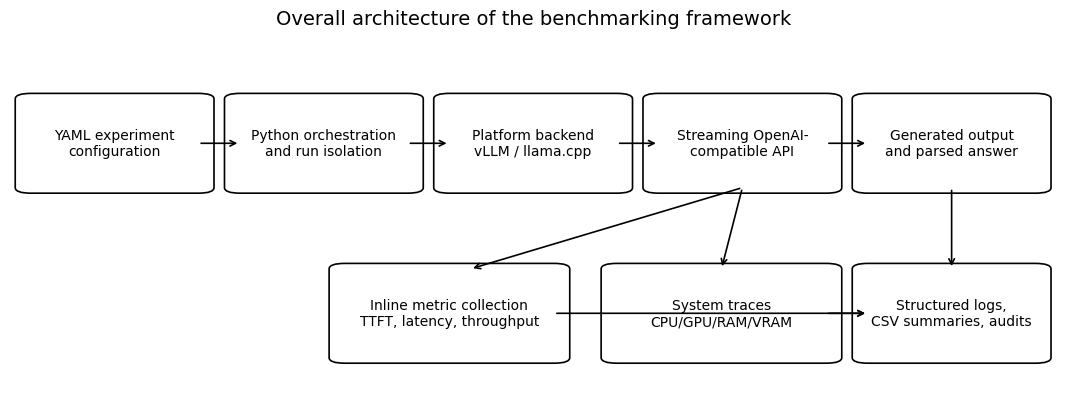

(PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_01_framework_architecture.png'),
 PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_01_framework_architecture.pdf'))

In [8]:

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.set_axis_off()

boxes = [
    (0.02, 0.58, 0.16, 0.24, "YAML experiment\nconfiguration"),
    (0.22, 0.58, 0.16, 0.24, "Python orchestration\nand run isolation"),
    (0.42, 0.58, 0.16, 0.24, "Platform backend\nvLLM / llama.cpp"),
    (0.62, 0.58, 0.16, 0.24, "Streaming OpenAI-\ncompatible API"),
    (0.82, 0.58, 0.16, 0.24, "Generated output\nand parsed answer"),
    (0.32, 0.12, 0.20, 0.24, "Inline metric collection\nTTFT, latency, throughput"),
    (0.58, 0.12, 0.20, 0.24, "System traces\nCPU/GPU/RAM/VRAM"),
    (0.82, 0.12, 0.16, 0.24, "Structured logs,\nCSV summaries, audits"),
]

for x, y, w, h, label in boxes:
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.015",
        linewidth=1.2,
        fill=False,
    )
    ax.add_patch(patch)
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=10)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops={"arrowstyle": "->", "lw": 1.2})

arrow(0.18, 0.70, 0.22, 0.70)
arrow(0.38, 0.70, 0.42, 0.70)
arrow(0.58, 0.70, 0.62, 0.70)
arrow(0.78, 0.70, 0.82, 0.70)
arrow(0.70, 0.58, 0.44, 0.36)
arrow(0.70, 0.58, 0.68, 0.36)
arrow(0.52, 0.24, 0.82, 0.24)
arrow(0.78, 0.24, 0.82, 0.24)
arrow(0.90, 0.58, 0.90, 0.36)

ax.set_title("Overall architecture of the benchmarking framework", fontsize=14)
save_figure(fig, "figure_01_framework_architecture")


## 8. Figures 2–3: context-specific peak system RAM

These figures report **system RAM** only for the edge and local-CPU contexts. GPU memory is handled separately as VRAM in the frontier and resource tables.


saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_02_pi5_peak_system_ram.png


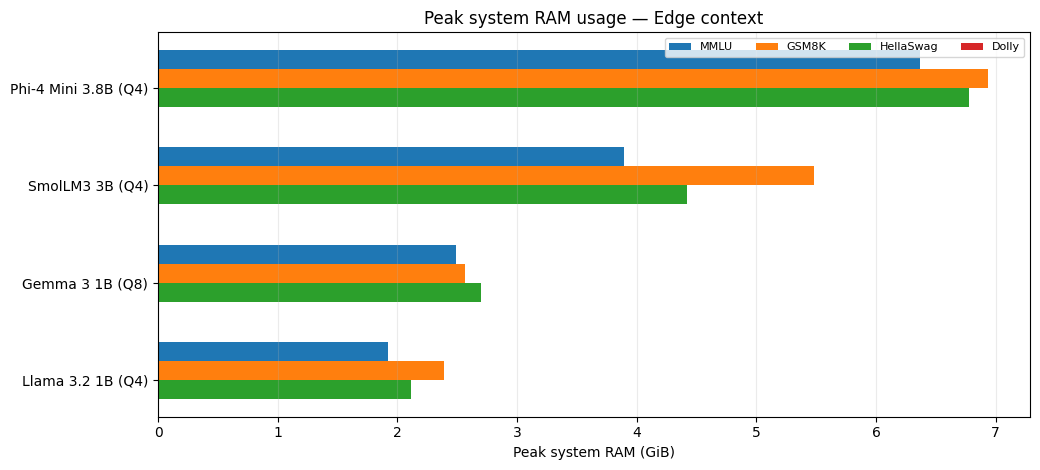

saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_03_cpu_peak_system_ram.png


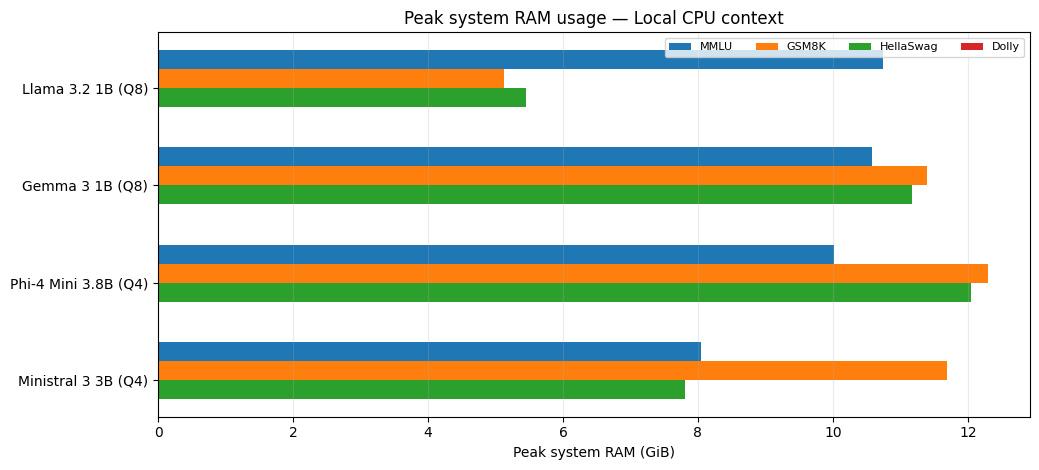

In [9]:

def plot_context_ram(context: str, figure_number: int, stem: str):
    frame = context_subset(context)
    if "ram_used_mb_peak" not in frame.columns:
        print("RAM metric unavailable; skipping", stem)
        return

    pivot = (
        frame.pivot_table(
            index="model_display_canonical",
            columns="dataset",
            values="ram_used_mb_peak",
            aggfunc="mean",
        )
        .reindex(columns=[d for d in ALL_WORKLOADS if d in frame["dataset"].unique()])
        / 1024.0
    )
    pivot = pivot.sort_values(
        by=list(pivot.columns),
        ascending=False,
        na_position="last",
    )

    fig, ax = plt.subplots(figsize=(10.5, max(4.8, 0.62 * len(pivot) + 2)))
    y = np.arange(len(pivot))
    datasets = list(pivot.columns)
    height = 0.78 / max(len(datasets), 1)

    for i, dataset in enumerate(datasets):
        ax.barh(
            y + (i - (len(datasets) - 1) / 2) * height,
            pivot[dataset].to_numpy(),
            height=height,
            label=DATASET_DISPLAY.get(dataset, dataset),
        )

    ax.set_yticks(y)
    ax.set_yticklabels([short_name(v, 34) for v in pivot.index])
    ax.invert_yaxis()
    ax.set_xlabel("Peak system RAM (GiB)")
    ax.set_title(f"Peak system RAM usage — {CONTEXT_DISPLAY[context]} context")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(ncol=min(4, len(datasets)), fontsize=8)
    fig.tight_layout()
    save_figure(fig, stem)


plot_context_ram("edge", 2, "figure_02_pi5_peak_system_ram")
plot_context_ram("local_cpu", 3, "figure_03_cpu_peak_system_ram")


## 9. Figure 4: task-level accuracy by deployment context

A dot plot is used instead of a dense bar chart. Each panel represents one context, so the model sets are not implied to be fully crossed across hardware.


saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_04_accuracy_by_context_and_dataset.png


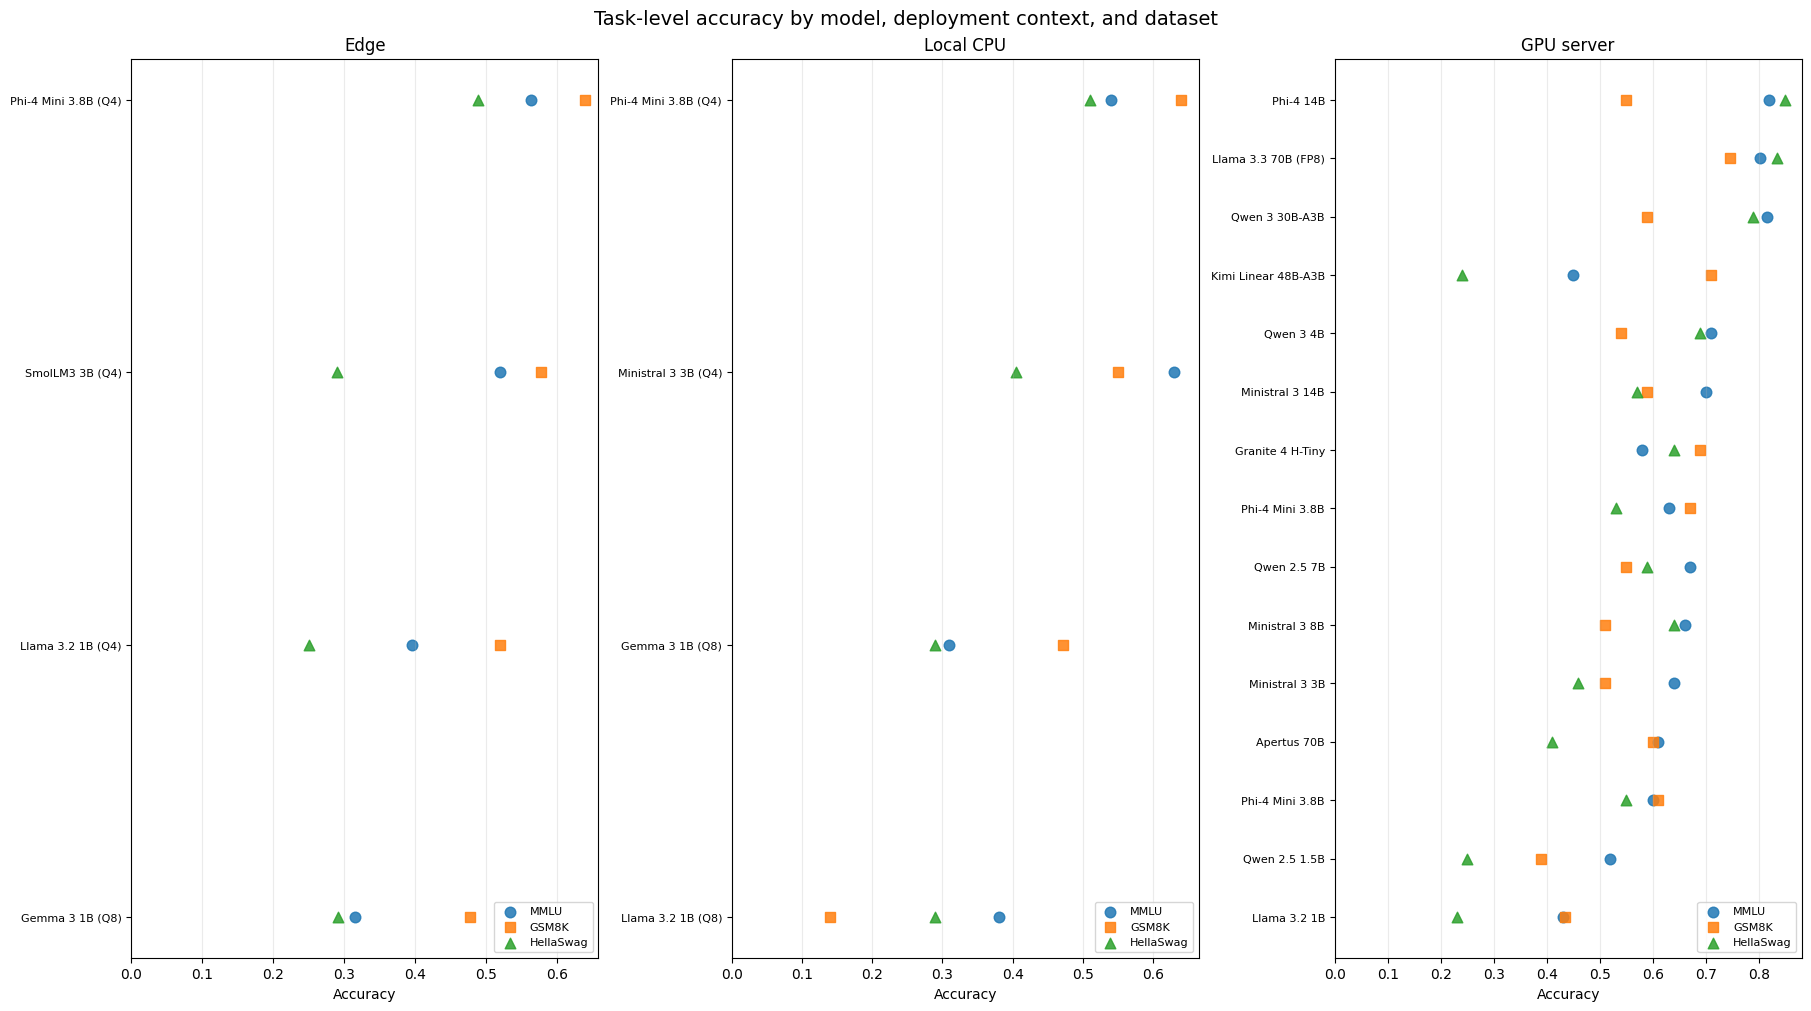

(PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_04_accuracy_by_context_and_dataset.png'),
 PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_04_accuracy_by_context_and_dataset.pdf'))

In [10]:

scored = agg[agg["dataset"].isin(SCORED_DATASETS) & agg["accuracy"].notna()].copy()

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 10),
    squeeze=False,
    constrained_layout=True,
)

dataset_markers = {"mmlu": "o", "gsm8k": "s", "hellaswag": "^"}

for ax, context in zip(axes[0], CONTEXT_ORDER):
    sub = scored[scored["context"].eq(context)].copy()
    model_order = (
        sub.groupby("model_display_canonical")["accuracy"]
        .max()
        .sort_values()
        .index
        .tolist()
    )
    ymap = {model: i for i, model in enumerate(model_order)}

    for dataset in SCORED_DATASETS:
        g = sub[sub["dataset"].eq(dataset)]
        ax.scatter(
            g["accuracy"],
            g["model_display_canonical"].map(ymap),
            marker=dataset_markers[dataset],
            s=58,
            alpha=0.85,
            label=DATASET_DISPLAY[dataset],
        )

    ax.set_yticks(range(len(model_order)))
    ax.set_yticklabels([short_name(v, 31) for v in model_order], fontsize=8)
    ax.set_xlim(left=0)
    ax.set_xlabel("Accuracy")
    ax.set_title(CONTEXT_DISPLAY[context])
    ax.grid(axis="x", alpha=0.25)
    ax.legend(fontsize=8, loc="lower right")

fig.suptitle("Task-level accuracy by model, deployment context, and dataset", fontsize=14)
save_figure(fig, "figure_04_accuracy_by_context_and_dataset")


## 10. Figure 5: sustained throughput across contexts and workloads

The x-axis is logarithmic because throughput spans approximately two orders of magnitude.


saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_05_sustained_throughput_across_contexts.png


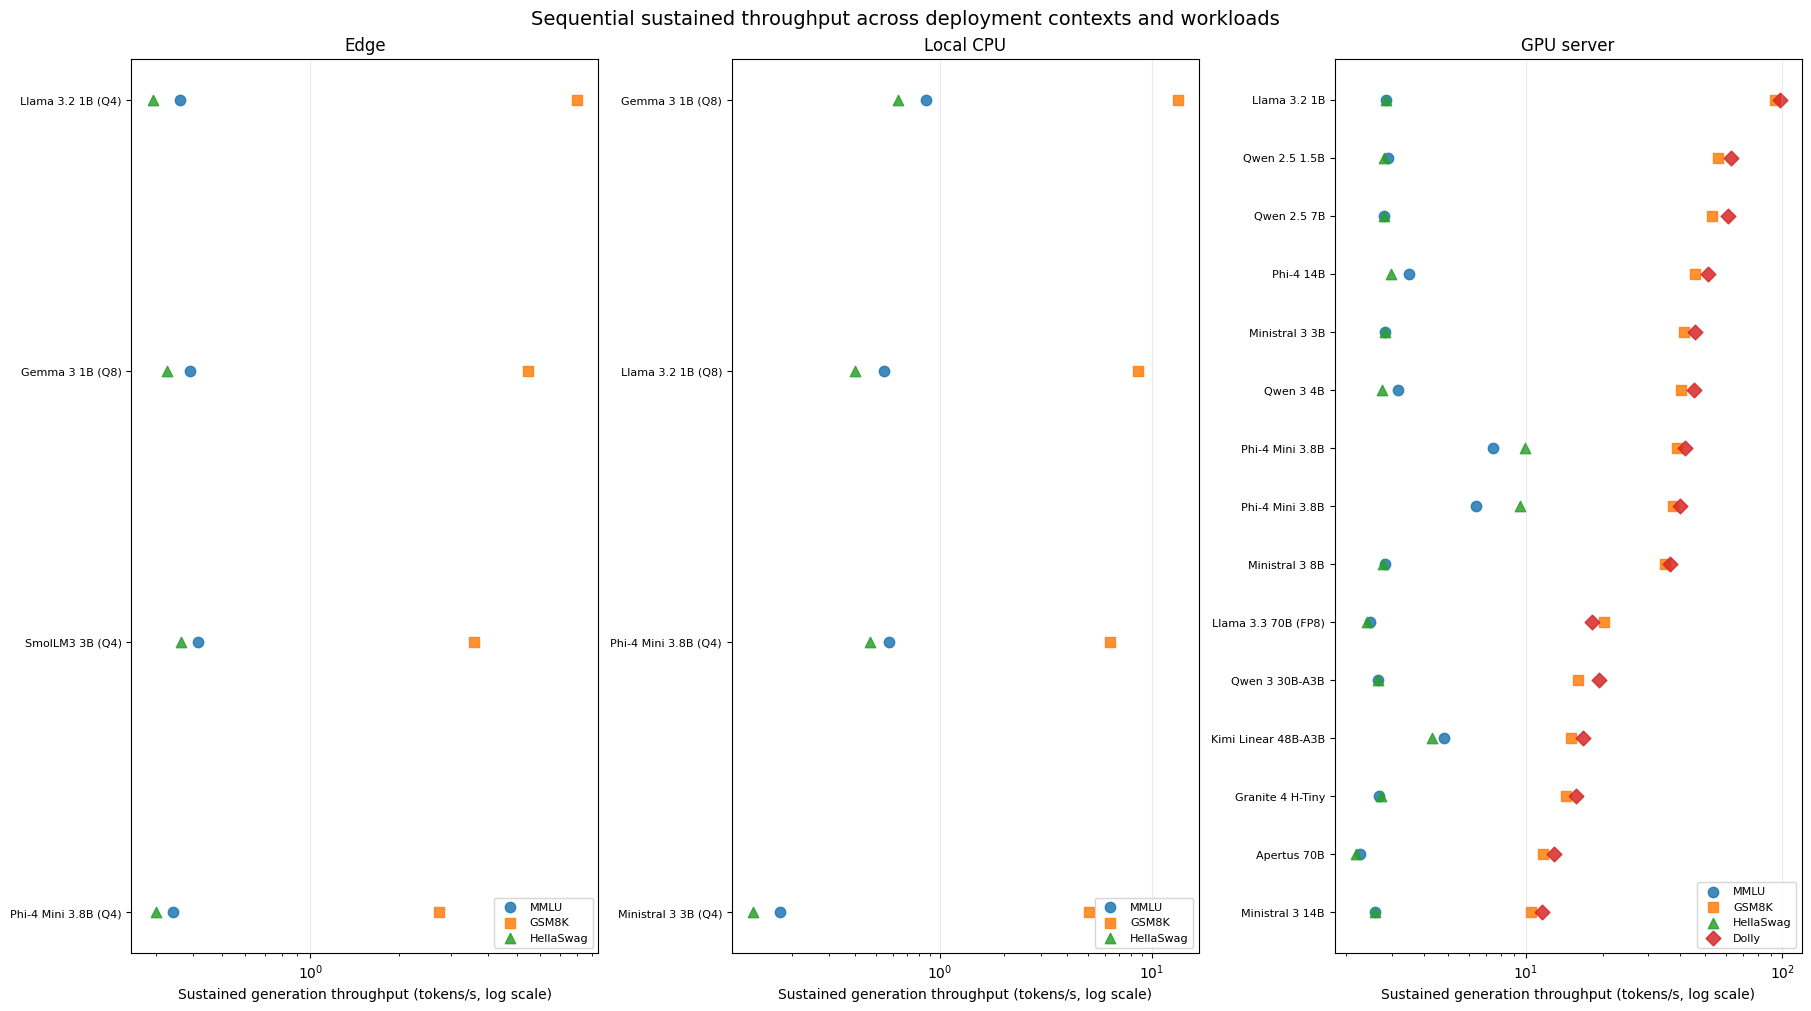

(PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_05_sustained_throughput_across_contexts.png'),
 PosixPath('/home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_05_sustained_throughput_across_contexts.pdf'))

In [11]:

throughput_metric = (
    "sustained_tokens_per_sec"
    if "sustained_tokens_per_sec" in agg.columns
    else "tokens_per_sec"
)

throughput_frame = agg[agg[throughput_metric].notna()].copy()

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 10),
    squeeze=False,
    constrained_layout=True,
)

workload_markers = {"mmlu": "o", "gsm8k": "s", "hellaswag": "^", "dolly": "D"}

for ax, context in zip(axes[0], CONTEXT_ORDER):
    sub = throughput_frame[throughput_frame["context"].eq(context)].copy()
    model_order = (
        sub.groupby("model_display_canonical")[throughput_metric]
        .max()
        .sort_values()
        .index
        .tolist()
    )
    ymap = {model: i for i, model in enumerate(model_order)}

    for dataset in ALL_WORKLOADS:
        g = sub[sub["dataset"].eq(dataset)]
        if g.empty:
            continue
        ax.scatter(
            g[throughput_metric],
            g["model_display_canonical"].map(ymap),
            marker=workload_markers[dataset],
            s=56,
            alpha=0.85,
            label=DATASET_DISPLAY[dataset],
        )

    ax.set_yticks(range(len(model_order)))
    ax.set_yticklabels([short_name(v, 31) for v in model_order], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Sustained generation throughput (tokens/s, log scale)")
    ax.set_title(CONTEXT_DISPLAY[context])
    ax.grid(axis="x", alpha=0.25)
    ax.legend(fontsize=8, loc="lower right")

fig.suptitle("Sequential sustained throughput across deployment contexts and workloads", fontsize=14)
save_figure(fig, "figure_05_sustained_throughput_across_contexts")


## 11. Figures 6–7: GSM8K context-local Pareto frontiers

The panels are intentionally context-specific. A GPU point may globally dominate a CPU point, but that comparison is not actionable when GPU access is unavailable.


saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_06_gsm8k_accuracy_latency_frontiers.png


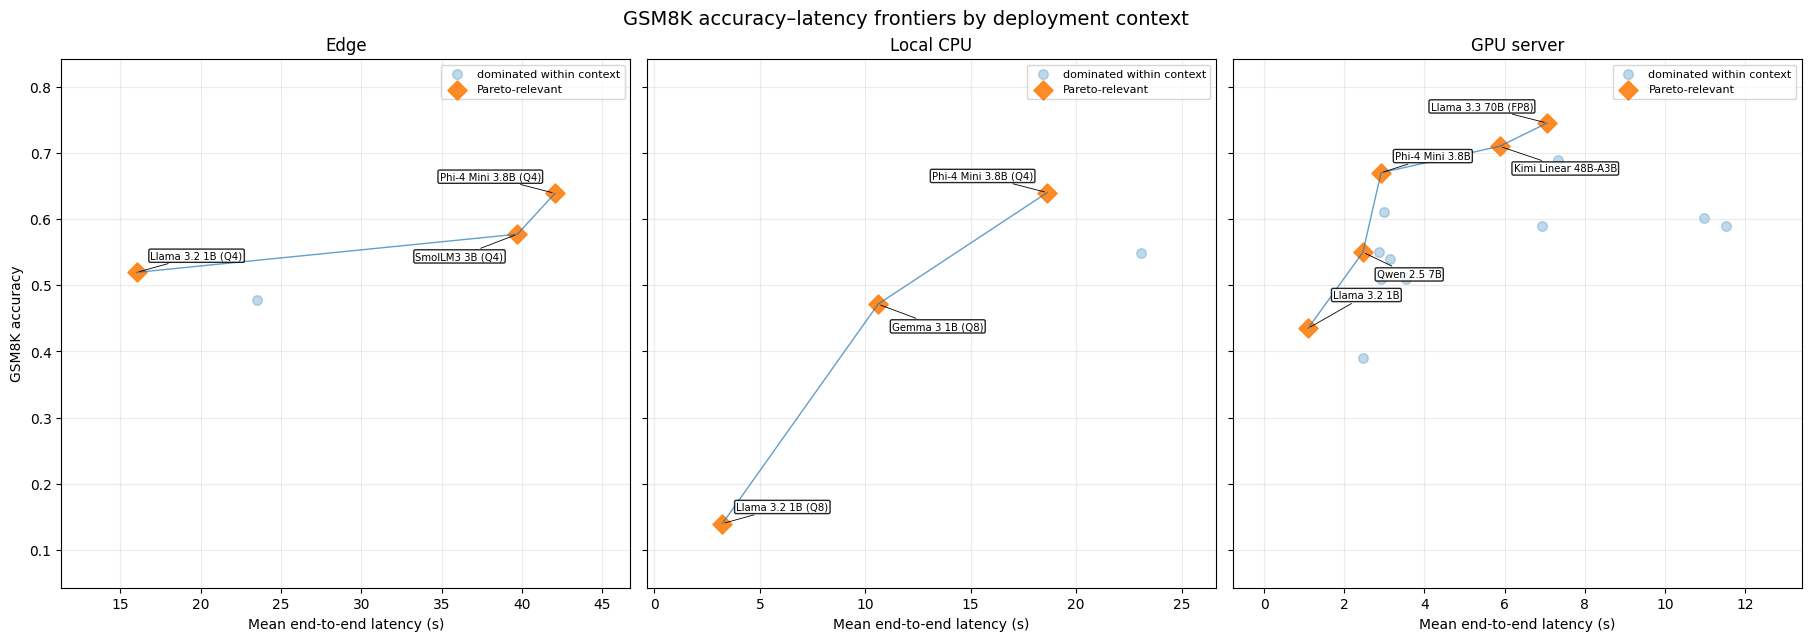

saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/figure_07_gsm8k_accuracy_memory_frontiers.png


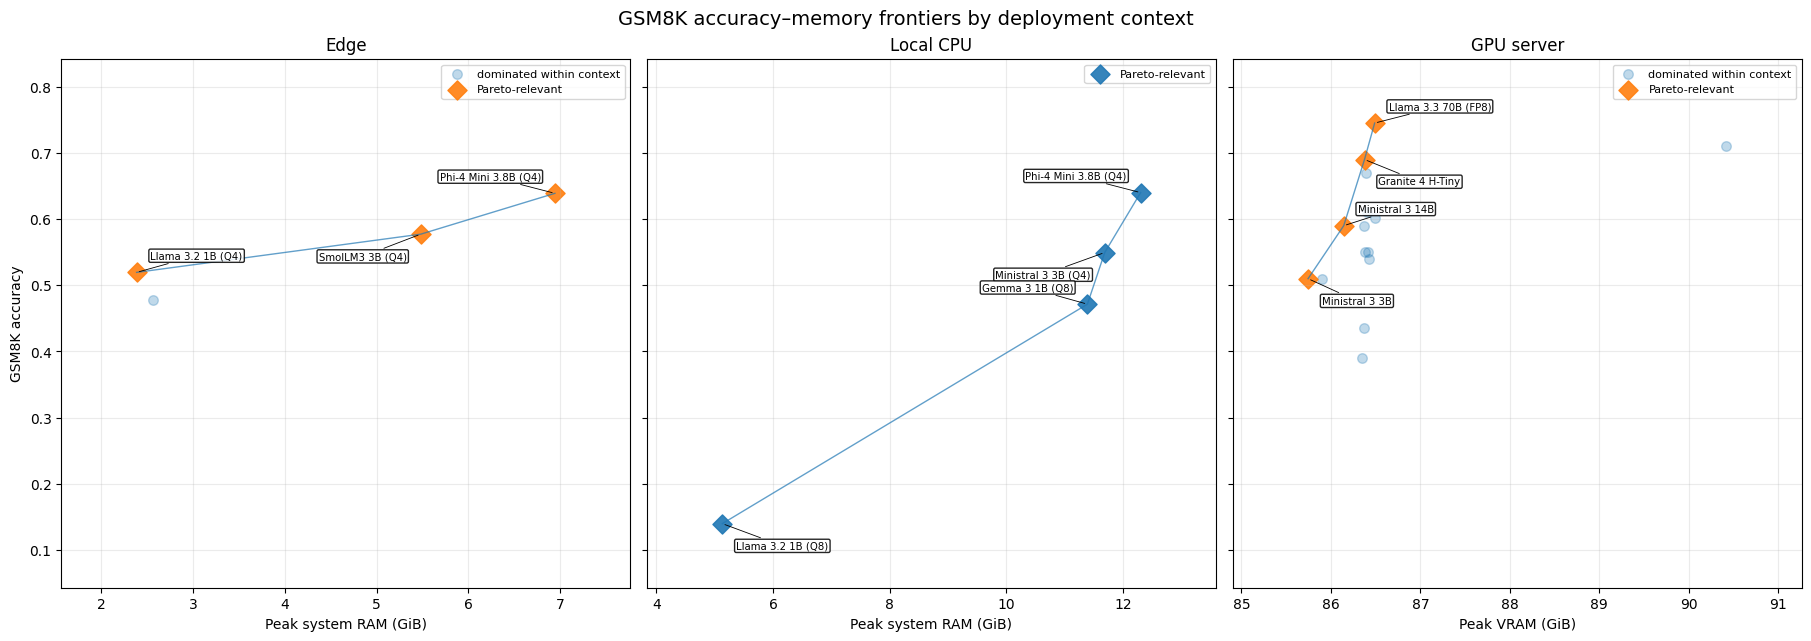

,frontier,context,dataset,model,pareto,accuracy,x_metric,x_value
0,figure_06_gsm8k_accuracy_latency_frontiers,edge,gsm8k,Phi-4 Mini 3.8B (Q4),True,0.6389,latency_s,42.039668
1,figure_06_gsm8k_accuracy_latency_frontiers,edge,gsm8k,SmolLM3 3B (Q4),True,0.5772,latency_s,39.710624
3,figure_06_gsm8k_accuracy_latency_frontiers,edge,gsm8k,Llama 3.2 1B (Q4),True,0.5195,latency_s,16.013137
4,figure_06_gsm8k_accuracy_latency_frontiers,local_cpu,gsm8k,Llama 3.2 1B (Q8),True,0.1400,latency_s,3.220719
6,figure_06_gsm8k_accuracy_latency_frontiers,local_cpu,gsm8k,Phi-4 Mini 3.8B (Q4),True,0.6400,latency_s,18.628568
7,figure_06_gsm8k_accuracy_latency_frontiers,local_cpu,gsm8k,Gemma 3 1B (Q8),True,0.4715,latency_s,10.607470
10,figure_06_gsm8k_accuracy_latency_frontiers,gpu_server,gsm8k,Kimi Linear 48B-A3B (bf16),True,0.7100,latency_s,5.874968
11,figure_06_gsm8k_accuracy_latency_frontiers,gpu_server,gsm8k,Llama 3.2 1B (bf16),True,0.4350,latency_s,1.097979
12,figure_06_gsm8k_accuracy_latency_frontiers,gpu_server,gsm8k,Llama 3.3 70B (FP8),True,0.7450,latency_s,7.057812
17,figure_06_gsm8k_accuracy_latency_frontiers,gpu_server,gsm8k,Phi-4 Mini 3.8B (bf16),True,0.6700,latency_s,2.917930


In [12]:

gsm = agg[agg["dataset"].eq("gsm8k") & agg["accuracy"].notna()].copy()

pareto_records = []

def plot_context_frontier(
    frame: pd.DataFrame,
    x: str,
    maximize_x: bool,
    xlabel_by_context: dict,
    title: str,
    stem: str,
):
    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 6.3),
        squeeze=False,
        constrained_layout=True,
        sharey=True,
    )

    for ax, context in zip(axes[0], CONTEXT_ORDER):
        sub = frame[frame["context"].eq(context)].dropna(subset=[x, "accuracy"]).copy()
        if sub.empty:
            ax.set_visible(False)
            continue

        sub["pareto"] = pareto_mask(
            sub, x=x, y="accuracy",
            maximize_x=maximize_x,
            maximize_y=True,
        )

        for _, row in sub.iterrows():
            pareto_records.append({
                "frontier": stem,
                "context": context,
                "dataset": "gsm8k",
                "model": row["model_display_canonical"],
                "pareto": bool(row["pareto"]),
                "accuracy": row["accuracy"],
                "x_metric": x,
                "x_value": row[x],
            })

        dominated = sub[~sub["pareto"]]
        frontier = sub[sub["pareto"]].sort_values(x)

        if not dominated.empty:
            ax.scatter(
                dominated[x], dominated["accuracy"],
                s=48, alpha=0.28,
                label="dominated within context",
            )
        ax.scatter(
            frontier[x], frontier["accuracy"],
            s=95, marker="D", alpha=0.90,
            label="Pareto-relevant",
        )
        if len(frontier) > 1:
            ax.plot(frontier[x], frontier["accuracy"], linewidth=1.0, alpha=0.7)

        ax.margins(x=0.18, y=0.16)
        annotate_rows(ax, frontier, x=x, y="accuracy", max_labels=5)
        ax.set_xlabel(xlabel_by_context[context])
        ax.set_title(CONTEXT_DISPLAY[context])
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, loc="best")

    axes[0][0].set_ylabel("GSM8K accuracy")
    fig.suptitle(title, fontsize=14)
    save_figure(fig, stem)


plot_context_frontier(
    gsm,
    x="latency_s",
    maximize_x=False,
    xlabel_by_context={c: "Mean end-to-end latency (s)" for c in CONTEXT_ORDER},
    title="GSM8K accuracy–latency frontiers by deployment context",
    stem="figure_06_gsm8k_accuracy_latency_frontiers",
)

plot_context_frontier(
    gsm,
    x="deployment_memory_gib",
    maximize_x=False,
    xlabel_by_context={
        "edge": "Peak system RAM (GiB)",
        "local_cpu": "Peak system RAM (GiB)",
        "gpu_server": "Peak VRAM (GiB)",
    },
    title="GSM8K accuracy–memory frontiers by deployment context",
    stem="figure_07_gsm8k_accuracy_memory_frontiers",
)

pareto_table = pd.DataFrame(pareto_records)
pareto_table.to_csv(TABLE_DIR / "gsm8k_context_pareto_membership.csv", index=False)
display(pareto_table[pareto_table["pareto"]])


## 12. Tables 4–7: empirical manuscript tables

Both full and selected versions are exported. The selected versions remain readable in a two-column IEEE layout.


In [13]:

# Representative order used in the current manuscript.
REPRESENTATIVE_MODELS = OrderedDict({
    "edge": [
        "Llama 3.2 1B (Q4)",
        "Gemma 3 1B (Q8)",
        "SmolLM3 3B (Q4)",
        "Phi-4 Mini 3.8B (Q4)",
    ],
    "local_cpu": [
        "Llama 3.2 1B (Q8)",
        "Gemma 3 1B (Q8)",
        "Phi-4 Mini 3.8B (Q4)",
        "Ministral 3 3B (Q4)",
    ],
    "gpu_server": [
        "Llama 3.2 1B (bf16)",
        "Qwen 2.5 1.5B (bf16)",
        "Ministral 3 3B (AWQ)",
        "Phi-4 Mini 3.8B (bf16)",
        "Ministral 3 8B (AWQ)",
        "Ministral 3 14B",
        "Phi-4 14B (bf16)",
        "Qwen 3 30B-A3B (bf16)",
        "Llama 3.3 70B (FP8)",
    ],
})

representative_pairs = {
    (context, model)
    for context, models in REPRESENTATIVE_MODELS.items()
    for model in models
}

def representative_filter(frame):
    return frame.apply(
        lambda r: (r["context"], r["model_display_canonical"]) in representative_pairs,
        axis=1,
    )


# Table 4 — selected task accuracy.
table_04_source = scored[representative_filter(scored)].copy()
table_04 = (
    table_04_source.pivot_table(
        index=["context_display", "model_display_canonical"],
        columns="dataset",
        values="accuracy",
        aggfunc="mean",
    )
    .reset_index()
    .rename(columns={
        "context_display": "Context",
        "model_display_canonical": "Model",
        "mmlu": "MMLU",
        "gsm8k": "GSM8K",
        "hellaswag": "HellaSwag",
    })
)
for col in ["MMLU", "GSM8K", "HellaSwag"]:
    if col not in table_04:
        table_04[col] = np.nan
table_04 = table_04[["Context", "Model", "MMLU", "GSM8K", "HellaSwag"]]

export_table(
    table_04,
    "table_04_task_accuracy_selected",
    "Task-level accuracy per deployment context and dataset. Values are aggregated across repeated runs.",
    "tab:task-accuracy",
)

# Full accuracy table for appendix/audit.
table_04_full = (
    scored.pivot_table(
        index=["context_display", "model_display_canonical"],
        columns="dataset",
        values="accuracy",
        aggfunc="mean",
    )
    .reset_index()
)
table_04_full.to_csv(TABLE_DIR / "table_04_task_accuracy_full.csv", index=False)


# Table 5 — representative timing/throughput rows.
TIMING_SELECTION = [
    ("edge", "Llama 3.2 1B (Q4)", "mmlu"),
    ("edge", "Llama 3.2 1B (Q4)", "gsm8k"),
    ("edge", "Phi-4 Mini 3.8B (Q4)", "mmlu"),
    ("edge", "Phi-4 Mini 3.8B (Q4)", "gsm8k"),
    ("local_cpu", "Gemma 3 1B (Q8)", "mmlu"),
    ("local_cpu", "Phi-4 Mini 3.8B (Q4)", "mmlu"),
    ("local_cpu", "Phi-4 Mini 3.8B (Q4)", "gsm8k"),
    ("local_cpu", "Ministral 3 3B (Q4)", "mmlu"),
    ("gpu_server", "Llama 3.2 1B (bf16)", "dolly"),
    ("gpu_server", "Llama 3.2 1B (bf16)", "gsm8k"),
    ("gpu_server", "Qwen 2.5 1.5B (bf16)", "dolly"),
    ("gpu_server", "Ministral 3 3B (AWQ)", "dolly"),
    ("gpu_server", "Phi-4 Mini 3.8B (bf16)", "dolly"),
    ("gpu_server", "Ministral 3 8B (AWQ)", "dolly"),
    ("gpu_server", "Phi-4 14B (bf16)", "dolly"),
    ("gpu_server", "Ministral 3 14B", "dolly"),
    ("gpu_server", "Qwen 3 30B-A3B (bf16)", "dolly"),
    ("gpu_server", "Llama 3.3 70B (FP8)", "dolly"),
    ("gpu_server", "Apertus 70B (bf16)", "dolly"),
]
timing_keys = set(TIMING_SELECTION)
timing_selected = agg[
    agg.apply(
        lambda r: (
            r["context"], r["model_display_canonical"], r["dataset"]
        ) in timing_keys,
        axis=1,
    )
].copy()

table_05 = timing_selected[
    [
        "context_display", "model_display_canonical", "dataset",
        "ttft_ms", "latency_ms", "tokens_per_sec",
    ]
].rename(columns={
    "context_display": "Context",
    "model_display_canonical": "Model",
    "dataset": "Dataset",
    "ttft_ms": "TTFT (ms)",
    "latency_ms": "Latency (ms)",
    "tokens_per_sec": "Tokens/s",
})
table_05["Dataset"] = table_05["Dataset"].map(DATASET_DISPLAY)

export_table(
    table_05,
    "table_05_timing_throughput_selected",
    "Mean time to first token, end-to-end latency, and token throughput for representative configurations.",
    "tab:timing-throughput",
)


# Table 6 — selected resources.
RESOURCE_SELECTION = [
    ("edge", "Llama 3.2 1B (Q4)", "mmlu"),
    ("edge", "Gemma 3 1B (Q8)", "mmlu"),
    ("edge", "SmolLM3 3B (Q4)", "mmlu"),
    ("edge", "Phi-4 Mini 3.8B (Q4)", "mmlu"),
    ("local_cpu", "Llama 3.2 1B (Q8)", "gsm8k"),
    ("local_cpu", "Gemma 3 1B (Q8)", "mmlu"),
    ("local_cpu", "Phi-4 Mini 3.8B (Q4)", "mmlu"),
    ("local_cpu", "Ministral 3 3B (Q4)", "mmlu"),
    ("gpu_server", "Llama 3.2 1B (bf16)", "dolly"),
    ("gpu_server", "Phi-4 Mini 3.8B (bf16)", "dolly"),
    ("gpu_server", "Phi-4 14B (bf16)", "dolly"),
    ("gpu_server", "Ministral 3 14B", "dolly"),
    ("gpu_server", "Qwen 3 30B-A3B (bf16)", "dolly"),
    ("gpu_server", "Kimi Linear 48B-A3B (bf16)", "dolly"),
    ("gpu_server", "Llama 3.3 70B (FP8)", "dolly"),
    ("gpu_server", "Apertus 70B (bf16)", "dolly"),
]
resource_keys = set(RESOURCE_SELECTION)
resource_selected = agg[
    agg.apply(
        lambda r: (
            r["context"], r["model_display_canonical"], r["dataset"]
        ) in resource_keys,
        axis=1,
    )
].copy()

resource_cols = [
    "context_display", "model_display_canonical", "dataset",
    "cpu_percent_peak", "ram_used_mb_peak", "vram_used_mb_peak",
    "temperature_c_peak",
]
resource_cols = [c for c in resource_cols if c in resource_selected.columns]
table_06 = resource_selected[resource_cols].rename(columns={
    "context_display": "Context",
    "model_display_canonical": "Model",
    "dataset": "Dataset",
    "cpu_percent_peak": "CPU peak (%)",
    "ram_used_mb_peak": "RAM peak (MB)",
    "vram_used_mb_peak": "VRAM peak (MB)",
    "temperature_c_peak": "Temperature peak (°C)",
})
table_06["Dataset"] = table_06["Dataset"].map(DATASET_DISPLAY)

export_table(
    table_06,
    "table_06_peak_resources_selected",
    "Peak resource utilization for representative configurations.",
    "tab:peak-resources",
)


# Table 7 — corrected and explicitly defined cost-effectiveness metric.
mmlu = agg[agg["dataset"].eq("mmlu") & agg["accuracy"].notna()].copy()
mmlu_selected = mmlu[representative_filter(mmlu)].copy()

table_07 = mmlu_selected[
    [
        "context_display", "model_display_canonical", "accuracy",
        "latency_s", "tokens_per_sec", "samples_per_sec",
        "expected_correct_per_second",
    ]
].rename(columns={
    "context_display": "Context",
    "model_display_canonical": "Model",
    "accuracy": "Accuracy",
    "latency_s": "Latency (s)",
    "tokens_per_sec": "Tokens/s",
    "samples_per_sec": "Samples/s",
    "expected_correct_per_second": "Expected correct responses/s",
})

export_table(
    table_07,
    "table_07_cost_effectiveness_mmlu",
    "Cost-effectiveness on MMLU. Expected correct responses per second is accuracy multiplied by measured samples per second; it is reported only as a short-output sequential-workload indicator.",
    "tab:cost-effectiveness",
)

display(table_04)
display(table_05)
display(table_06)
display(table_07)


dataset,Context,Model,MMLU,GSM8K,HellaSwag
0,Edge,Gemma 3 1B (Q8),0.315,0.4773,0.291
1,Edge,Llama 3.2 1B (Q4),0.395,0.5195,0.251
2,Edge,Phi-4 Mini 3.8B (Q4),0.564,0.6389,0.489
3,Edge,SmolLM3 3B (Q4),0.520,0.5772,0.290
4,GPU server,Llama 3.2 1B (bf16),0.430,0.4350,0.230
5,GPU server,Llama 3.3 70B (FP8),0.802,0.7450,0.835
6,GPU server,Ministral 3 14B,0.700,0.5900,0.570
7,GPU server,Ministral 3 3B (AWQ),0.640,0.5100,0.460
8,GPU server,Ministral 3 8B (AWQ),0.660,0.5100,0.640
9,GPU server,Phi-4 14B (bf16),0.820,0.5500,0.850


,Context,Model,Dataset,TTFT (ms),Latency (ms),Tokens/s
8,GPU server,Apertus 70B (bf16),Dolly,213.31360,10525.29590,12.90070
11,GPU server,Llama 3.2 1B (bf16),Dolly,128.87260,1119.79890,116.88760
12,GPU server,Llama 3.3 70B (FP8),Dolly,182.22170,6287.66610,18.46820
13,GPU server,Ministral 3 14B,Dolly,164.50040,9962.04440,11.83460
14,GPU server,Ministral 3 3B (AWQ),Dolly,132.15950,2529.81070,49.81610
15,GPU server,Ministral 3 8B (AWQ),Dolly,135.21890,3201.72470,38.92230
16,GPU server,Phi-4 14B (bf16),Dolly,144.27450,2478.37450,55.73000
17,GPU server,Phi-4 Mini 3.8B (bf16),Dolly,140.12950,2544.97750,44.17830
19,GPU server,Qwen 2.5 1.5B (bf16),Dolly,132.09060,1604.32650,69.21460
21,GPU server,Qwen 3 30B-A3B (bf16),Dolly,155.05630,6103.13540,19.72060


,Context,Model,Dataset,CPU peak (%),RAM peak (MB),VRAM peak (MB),Temperature peak (°C)
8,GPU server,Apertus 70B (bf16),Dolly,5.700000,15629.59,88571.0,51.000000
10,GPU server,Kimi Linear 48B-A3B (bf16),Dolly,6.600000,16061.17,92595.0,54.000000
11,GPU server,Llama 3.2 1B (bf16),Dolly,5.400000,15489.59,88447.0,54.000000
12,GPU server,Llama 3.3 70B (FP8),Dolly,5.900000,16164.48,88565.0,53.000000
13,GPU server,Ministral 3 14B,Dolly,5.100000,16501.00,88211.0,54.000000
16,GPU server,Phi-4 14B (bf16),Dolly,6.200000,15103.59,88487.0,52.000000
17,GPU server,Phi-4 Mini 3.8B (bf16),Dolly,5.500000,15451.22,88467.0,54.000000
21,GPU server,Qwen 3 30B-A3B (bf16),Dolly,5.200000,16013.15,88447.0,54.000000
23,Local CPU,Llama 3.2 1B (Q8),GSM8K,30.400000,5254.59,NaN,100.000000
70,Local CPU,Ministral 3 3B (Q4),MMLU,63.750000,8231.27,NaN,90.500000


,Context,Model,Accuracy,Latency (s),Tokens/s,Samples/s,Expected correct responses/s
69,Local CPU,Llama 3.2 1B (Q8),0.380,1.820876,18.13930,0.538300,0.204554
70,Local CPU,Ministral 3 3B (Q4),0.630,5.702325,8.34790,0.176600,0.111258
71,Local CPU,Phi-4 Mini 3.8B (Q4),0.540,4.396023,8.68020,0.229333,0.123840
72,Local CPU,Gemma 3 1B (Q8),0.310,1.128218,13.25345,0.862750,0.267452
73,Edge,Phi-4 Mini 3.8B (Q4),0.564,6.552354,3.55010,0.132500,0.074730
74,Edge,SmolLM3 3B (Q4),0.520,5.666357,4.64160,0.150200,0.078104
75,Edge,Gemma 3 1B (Q8),0.315,1.566485,5.40540,0.390700,0.123070
76,Edge,Llama 3.2 1B (Q4),0.395,1.775791,12.69710,0.361200,0.142674
80,GPU server,Llama 3.2 1B (bf16),0.430,0.239430,9.07630,2.862300,1.230789
81,GPU server,Llama 3.3 70B (FP8),0.802,0.295715,8.69800,2.469450,1.980499


## 13. Supplementary evidence: compact-model deltas versus context-local best accuracy

These outputs support statements such as “a compact model gives up *x* accuracy points for *y*× throughput” without mixing baselines across contexts.


saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/supplement_mmlu_compact_accuracy_latency_tradeoff.png


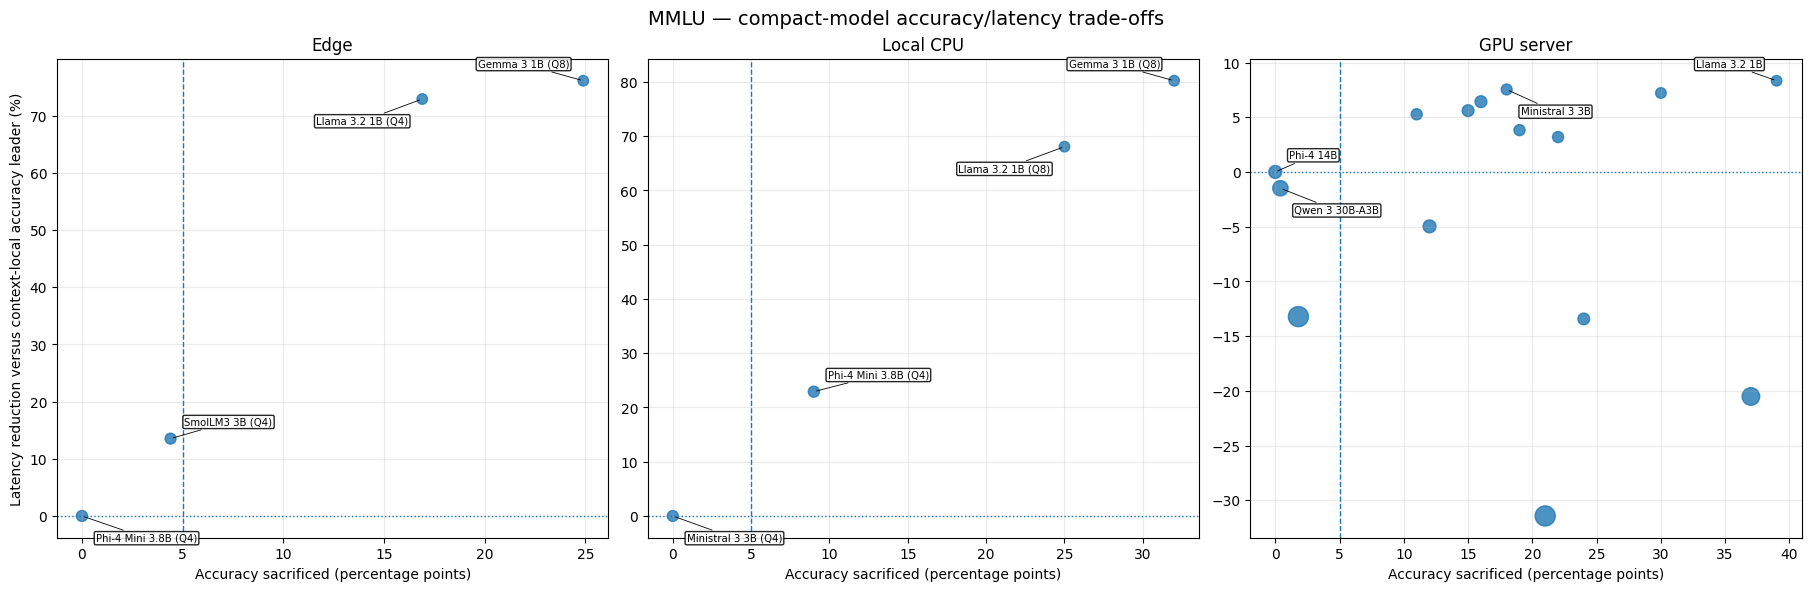

saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/supplement_gsm8k_compact_accuracy_latency_tradeoff.png


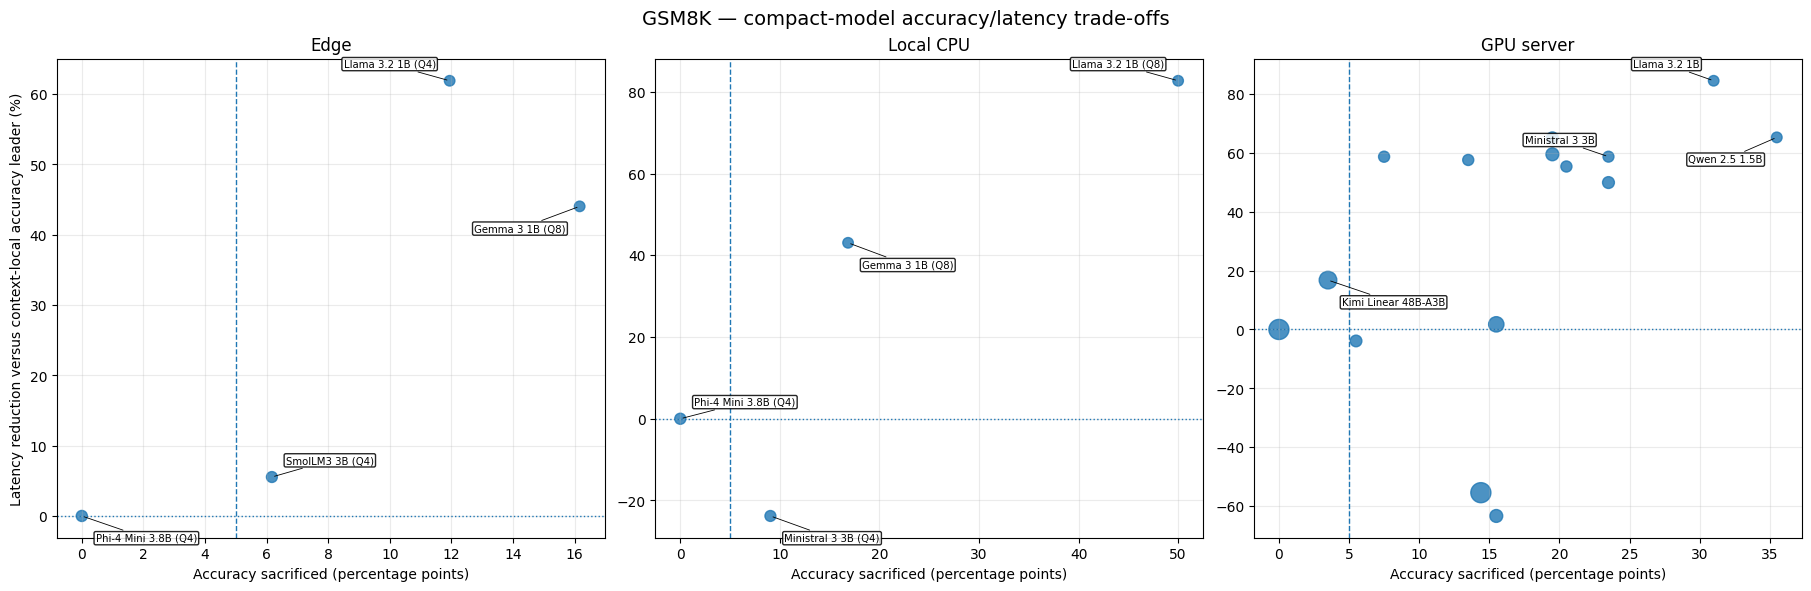

saved: /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6/figures/supplement_hellaswag_compact_accuracy_latency_tradeoff.png


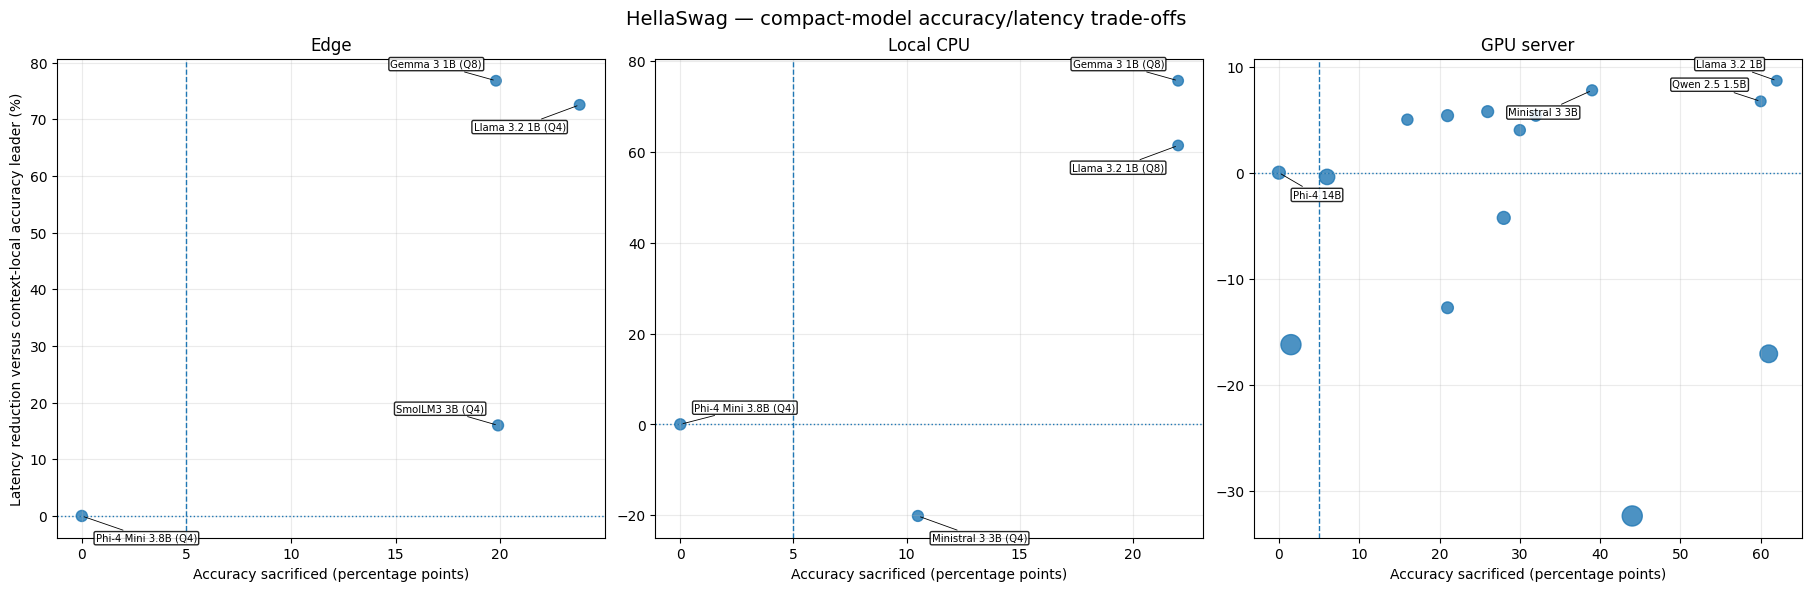

,dataset,context_display,model_display_canonical,total_parameters_b,reference_model,accuracy,reference_accuracy,accuracy_loss_pp,accuracy_retained_pct,throughput_speedup_x,latency_reduction_pct


In [14]:

def safe_ratio(numerator, denominator):
    return np.where(
        pd.notna(denominator) & (denominator != 0),
        numerator / denominator,
        np.nan,
    )


delta_parts = []
for (dataset, context), group in scored.groupby(["dataset", "context"], sort=False):
    g = group.copy()
    reference = g.loc[g["accuracy"].idxmax()]
    g["reference_model"] = reference["model_display_canonical"]
    g["reference_accuracy"] = reference["accuracy"]
    g["accuracy_loss_pp"] = 100.0 * (reference["accuracy"] - g["accuracy"])
    g["accuracy_retained_pct"] = 100.0 * safe_ratio(
        g["accuracy"], reference["accuracy"]
    )
    if "tokens_per_sec" in g.columns:
        g["throughput_speedup_x"] = safe_ratio(
            g["tokens_per_sec"], reference["tokens_per_sec"]
        )
    if "latency_ms" in g.columns:
        g["latency_reduction_pct"] = 100.0 * (
            1.0 - safe_ratio(g["latency_ms"], reference["latency_ms"])
        )
    g["competitive_95"] = (
        g["accuracy_retained_pct"] >= 100 * ACCURACY_RETENTION_THRESHOLD
    )
    delta_parts.append(g)

delta = pd.concat(delta_parts, ignore_index=True)
delta.to_csv(TABLE_DIR / "supplement_context_local_deltas.csv", index=False)

competitive_compact = delta[
    delta["compact_total"]
    & delta["competitive_95"]
    & (delta["accuracy_loss_pp"] > 1e-9)
].copy()
competitive_compact.to_csv(
    TABLE_DIR / "supplement_competitive_compact_models.csv",
    index=False,
)

for dataset in SCORED_DATASETS:
    sub = delta[delta["dataset"].eq(dataset)].copy()
    fig, axes = plt.subplots(
        1, 3, figsize=(18, 5.8), squeeze=False,
        constrained_layout=True, sharey=False,
    )
    for ax, context in zip(axes[0], CONTEXT_ORDER):
        g = sub[sub["context"].eq(context)].dropna(
            subset=["accuracy_loss_pp", "latency_reduction_pct"]
        )
        if g.empty:
            ax.set_visible(False)
            continue
        ax.scatter(
            g["accuracy_loss_pp"], g["latency_reduction_pct"],
            s=55 + 2.2 * g["total_parameters_b"].fillna(0),
            alpha=0.80,
        )
        threshold = 100 * (1 - ACCURACY_RETENTION_THRESHOLD)
        ax.axvline(threshold, linestyle="--", linewidth=1)
        ax.axhline(0, linestyle=":", linewidth=1)
        label_frame = g[
            g["competitive_95"] | g["compact_total"]
        ].sort_values(["competitive_95", "latency_reduction_pct"], ascending=False)
        annotate_rows(
            ax, label_frame.head(5),
            x="accuracy_loss_pp", y="latency_reduction_pct",
            max_labels=4,
        )
        ax.set_title(CONTEXT_DISPLAY[context])
        ax.set_xlabel("Accuracy sacrificed (percentage points)")
        ax.grid(alpha=0.25)
    axes[0][0].set_ylabel("Latency reduction versus context-local accuracy leader (%)")
    fig.suptitle(
        f"{DATASET_DISPLAY[dataset]} — compact-model accuracy/latency trade-offs",
        fontsize=14,
    )
    save_figure(fig, f"supplement_{dataset}_compact_accuracy_latency_tradeoff")

display(competitive_compact[
    [
        "dataset", "context_display", "model_display_canonical",
        "total_parameters_b", "reference_model",
        "accuracy", "reference_accuracy", "accuracy_loss_pp",
        "accuracy_retained_pct", "throughput_speedup_x",
        "latency_reduction_pct",
    ]
])


## 14. Canonical facts and manuscript text documents

The text files below are generated from the current CSV. They are intended as source material for revision—not as claims to copy without checking the confidence intervals and methodological caveats.


In [15]:

def fmt(value, digits=3):
    return "NA" if pd.isna(value) else f"{value:.{digits}f}"


fact_rows = []

# Per-context and per-dataset leaders.
for context in CONTEXT_ORDER:
    for dataset in SCORED_DATASETS:
        g = agg[
            agg["context"].eq(context)
            & agg["dataset"].eq(dataset)
            & agg["accuracy"].notna()
        ].copy()
        if g.empty:
            continue

        accuracy_leader = g.loc[g["accuracy"].idxmax()]
        latency_leader = g.loc[g["latency_ms"].idxmin()]
        throughput_leader = g.loc[g["tokens_per_sec"].idxmax()]

        fact_rows.extend([
            {
                "context": context,
                "dataset": dataset,
                "fact_type": "highest_accuracy",
                "model": accuracy_leader["model_display_canonical"],
                "value": accuracy_leader["accuracy"],
                "unit": "accuracy",
            },
            {
                "context": context,
                "dataset": dataset,
                "fact_type": "lowest_latency",
                "model": latency_leader["model_display_canonical"],
                "value": latency_leader["latency_ms"],
                "unit": "ms",
            },
            {
                "context": context,
                "dataset": dataset,
                "fact_type": "highest_token_throughput",
                "model": throughput_leader["model_display_canonical"],
                "value": throughput_leader["tokens_per_sec"],
                "unit": "tokens/s",
            },
        ])

facts = pd.DataFrame(fact_rows)
facts.to_csv(TEXT_DIR / "canonical_results_facts.csv", index=False)


def context_paragraph(context: str) -> str:
    frame = agg[agg["context"].eq(context)].copy()
    model_count = frame["model_display_canonical"].nunique()
    scored_frame = frame[frame["dataset"].isin(SCORED_DATASETS)]

    lines = [
        f"### {CONTEXT_DISPLAY[context]} context",
        "",
        f"The evaluated set contains **{model_count} context-specific model configurations**.",
    ]

    if frame["deployment_memory_gib"].notna().any():
        memory = frame["deployment_memory_gib"].dropna()
        memory_type = frame["deployment_memory_type"].dropna().iloc[0]
        lines.append(
            f"Observed peak {memory_type} spans **{memory.min():.2f}–{memory.max():.2f} GiB** "
            "across workloads and configurations."
        )

    for dataset in SCORED_DATASETS:
        g = scored_frame[scored_frame["dataset"].eq(dataset)]
        if g.empty:
            continue
        acc = g.loc[g["accuracy"].idxmax()]
        fast = g.loc[g["latency_ms"].idxmin()]
        lines.append(
            f"On {DATASET_DISPLAY[dataset]}, **{acc['model_display_canonical']}** has the "
            f"highest observed accuracy ({acc['accuracy']:.3f}), while "
            f"**{fast['model_display_canonical']}** has the lowest mean end-to-end latency "
            f"({fast['latency_ms']/1000:.2f} s)."
        )

    return "\n".join(lines)


results_draft = "\n\n".join(context_paragraph(c) for c in CONTEXT_ORDER)

# GPU diagnostic facts.
gpu = agg[agg["context"].eq("gpu_server")]
gpu_ttft = gpu["ttft_ms"].dropna()
dolly_gpu = gpu[gpu["dataset"].eq("dolly")].dropna(subset=["tokens_per_sec"])
if not gpu_ttft.empty:
    results_draft += (
        "\n\n### GPU timing interpretation\n\n"
        f"Across the GPU configurations and workloads represented in the normalized table, "
        f"mean TTFT spans **{gpu_ttft.min():.1f}–{gpu_ttft.max():.1f} ms**. "
        "End-to-end latency and sustained generation throughput should therefore carry more "
        "weight than TTFT when outputs differ substantially in length."
    )
if not dolly_gpu.empty:
    fastest = dolly_gpu.loc[dolly_gpu["tokens_per_sec"].idxmax()]
    slowest = dolly_gpu.loc[dolly_gpu["tokens_per_sec"].idxmin()]
    results_draft += (
        f"\n\nOn Dolly, token throughput ranges from **{slowest['tokens_per_sec']:.1f}** "
        f"tokens/s for **{slowest['model_display_canonical']}** to "
        f"**{fastest['tokens_per_sec']:.1f}** tokens/s for "
        f"**{fastest['model_display_canonical']}**, making the long-generation workload "
        "more discriminative than short-answer benchmarks."
    )

(TEXT_DIR / "results_section_data_draft.md").write_text(results_draft + "\n", encoding="utf-8")


# Abstract evidence block.
best_by_context = []
for context in CONTEXT_ORDER:
    g = scored[scored["context"].eq(context)]
    if g.empty:
        continue
    best = g.loc[g["accuracy"].idxmax()]
    best_by_context.append(
        f"{CONTEXT_DISPLAY[context]}: {best['model_display_canonical']} "
        f"({DATASET_DISPLAY[best['dataset']]} accuracy {best['accuracy']:.3f})"
    )

abstract_block = f"""## Abstract evidence block

**Method facts.** The normalized analysis contains **{configuration_count} context/model configurations** across three deployment contexts and four workloads. Accuracy is available for MMLU, GSM8K, and HellaSwag; Dolly is treated as an open-ended generation workload.

**Result facts.** The accuracy-leading configuration changes by context and dataset. Examples from the current data are: {"; ".join(best_by_context)}. Context-local Pareto frontiers identify multiple relevant configurations rather than one universal winner.

**Interpretation.** The evidence supports a deployment-context-aware claim: feasibility and memory dominate on edge hardware, latency dominates on local CPU, and the GPU context exposes an accuracy–throughput trade-off. Avoid claiming that one model is globally best.
"""
(TEXT_DIR / "abstract_evidence_block.md").write_text(abstract_block, encoding="utf-8")

print((TEXT_DIR / "results_section_data_draft.md").read_text(encoding="utf-8")[:5000])


### Edge context

The evaluated set contains **4 context-specific model configurations**.
Observed peak system RAM spans **1.92–6.94 GiB** across workloads and configurations.
On MMLU, **Phi-4 Mini 3.8B (Q4)** has the highest observed accuracy (0.564), while **Gemma 3 1B (Q8)** has the lowest mean end-to-end latency (1.57 s).
On GSM8K, **Phi-4 Mini 3.8B (Q4)** has the highest observed accuracy (0.639), while **Llama 3.2 1B (Q4)** has the lowest mean end-to-end latency (16.01 s).
On HellaSwag, **Phi-4 Mini 3.8B (Q4)** has the highest observed accuracy (0.489), while **Gemma 3 1B (Q8)** has the lowest mean end-to-end latency (2.06 s).

### Local CPU context

The evaluated set contains **4 context-specific model configurations**.
Observed peak system RAM spans **5.13–12.31 GiB** across workloads and configurations.
On MMLU, **Ministral 3 3B (Q4)** has the highest observed accuracy (0.630), while **Gemma 3 1B (Q8)** has the lowest mean end-to-end latency (1.13 s).
On GSM8K, **Phi-4 Mini 3.

## 15. Captions, document map, and consistency audit

In [16]:

captions = OrderedDict({
    "Figure 1": (
        "Overall architecture of the benchmarking framework. Experiments are defined by "
        "configuration files and executed through a Python orchestration layer. Platform-specific "
        "vLLM and llama.cpp backends expose an OpenAI-compatible streaming API. Task-level and "
        "inline system-level metrics are recorded and exported as traceable structured artifacts."
    ),
    "Figure 2": (
        "Peak system RAM usage on the Raspberry Pi 5 across workloads and feasible model "
        "configurations. System memory defines the feasible model set in the edge context."
    ),
    "Figure 3": (
        "Peak system RAM usage on the local CPU platform across workloads and model configurations. "
        "Within the evaluated pool, latency rather than memory is the principal differentiator."
    ),
    "Figure 4": (
        "Task-level accuracy by model, deployment context, and benchmark. The evaluated model set "
        "differs by context; points should therefore be interpreted within each panel rather than "
        "as a fully crossed hardware experiment."
    ),
    "Figure 5": (
        "Sequential sustained generation throughput across deployment contexts and workloads. "
        "The logarithmic axis exposes the wide throughput range, especially on the Dolly "
        "open-ended generation workload."
    ),
    "Figure 6": (
        "GSM8K accuracy–latency Pareto frontiers within each deployment context. A model is "
        "Pareto-relevant when no other model in the same context is both more accurate and faster."
    ),
    "Figure 7": (
        "GSM8K accuracy–memory Pareto frontiers within each deployment context. Memory denotes "
        "peak system RAM for edge and local CPU, and peak VRAM for the GPU server."
    ),
})

caption_text = "# Manuscript figure captions\n\n" + "\n\n".join(
    f"**{name}.** {caption}" for name, caption in captions.items()
)
(TEXT_DIR / "manuscript_figure_captions.md").write_text(caption_text + "\n", encoding="utf-8")


count_warning = (
    f"The current normalized data contains {configuration_count} context/model configurations. "
    "The manuscript currently states nineteen. Reconcile the count by defining whether repeated "
    "precision/platform variants are separate configurations and by confirming which completed "
    "runs belong to the final study."
)

audit_items = [
    ("Model-count statement", count_warning, "REQUIRES CHECK" if configuration_count != 19 else "OK"),
    (
        "Table 7 metric definition",
        "Do not describe the indicator as accuracy divided by token throughput. This notebook "
        "defines expected correct responses per second as accuracy × measured samples/s. "
        "The metric is only suitable as a compact short-output sequential-workload indicator.",
        "CORRECTED",
    ),
    (
        "Cross-context Pareto language",
        "GPU points may dominate CPU/edge points globally, but those comparisons are not actionable "
        "when an accelerator is unavailable. Main claims and Figures 6–7 use context-local frontiers.",
        "CORRECTED",
    ),
    (
        "Memory terminology",
        "Use system RAM for edge/CPU and VRAM for GPU. Do not plot these as an unqualified common "
        "memory measure without identifying the resource type.",
        "CORRECTED",
    ),
    (
        "SLM/LLM metadata",
        "Use total parameters for catalog/model-size classification, active parameters for MoE "
        "compute interpretation, and measured RAM/VRAM for deployment footprint.",
        "CORRECTED",
    ),
    (
        "Phi-4 Mini metadata",
        "All Phi-4 Mini variants are registered as 3.8B dense models and are no longer excluded "
        "from compact-model evidence due to missing filename parsing.",
        "CORRECTED",
    ),
    (
        "Qwen 2.5 1.5B metadata",
        "qwen2_5_1_5b_bf16 is registered as 1.54B, not 5B.",
        "CORRECTED",
    ),
    (
        "MoE metadata",
        "Granite H-Tiny, Qwen3-30B-A3B, and Kimi Linear include both total and active parameter counts.",
        "CORRECTED",
    ),
    (
        "GPU VRAM interpretation",
        "If VRAM values are nearly constant across models, verify whether the measurement represents "
        "allocated/reserved device memory rather than model-specific incremental footprint before "
        "making model-memory claims.",
        "REQUIRES CHECK",
    ),
    (
        "Accuracy uncertainty",
        "Tables and prose report means. Add standard deviations or confidence intervals where space "
        "allows, especially for small differences and reduced 100-sample subsets.",
        "REQUIRES CHECK",
    ),
    (
        "Pi throughput caveat",
        "The one-second inter-request pause is excluded from active-generation throughput. Preserve "
        "the distinction between active throughput and continuous serving throughput.",
        "REQUIRES CHECK",
    ),
    (
        "Backend and quantization confound",
        "vLLM/bf16-fp8-AWQ on GPU and llama.cpp/GGUF on CPU-edge are deployment-realistic but not a "
        "controlled backend comparison. Keep this limitation explicit.",
        "REQUIRES CHECK",
    ),
]

audit_df = pd.DataFrame(audit_items, columns=["Item", "Required action", "Status"])
audit_df.to_csv(CHECK_DIR / "manuscript_consistency_audit.csv", index=False)
audit_md = "# Manuscript consistency audit\n\n" + markdown_table(audit_df) + "\n"
(CHECK_DIR / "manuscript_consistency_audit.md").write_text(audit_md, encoding="utf-8")


document_map = """# Manuscript evidence-pack map

## Main manuscript figures
- `figures/figure_01_framework_architecture.{png,pdf}`
- `figures/figure_02_pi5_peak_system_ram.{png,pdf}`
- `figures/figure_03_cpu_peak_system_ram.{png,pdf}`
- `figures/figure_04_accuracy_by_context_and_dataset.{png,pdf}`
- `figures/figure_05_sustained_throughput_across_contexts.{png,pdf}`
- `figures/figure_06_gsm8k_accuracy_latency_frontiers.{png,pdf}`
- `figures/figure_07_gsm8k_accuracy_memory_frontiers.{png,pdf}`

## Main manuscript tables
Each table is exported as CSV, Markdown, and LaTeX.
- Table 1: deployment contexts
- Table 2: evaluated model configurations and corrected metadata
- Table 3: hardware platforms
- Table 4: selected task-level accuracy
- Table 5: selected timing and throughput
- Table 6: selected peak resources
- Table 7: explicitly defined cost-effectiveness indicator

## Text-support documents
- `text/manuscript_figure_captions.md`
- `text/results_section_data_draft.md`
- `text/abstract_evidence_block.md`
- `text/canonical_results_facts.csv`

## Checks
- `checks/model_metadata_audit.csv`
- `checks/manuscript_consistency_audit.{csv,md}`
- `checks/output_manifest.csv`

## Supplement
- context-local compact-model delta figures;
- context-local delta CSV;
- competitive compact-model evidence CSV;
- GSM8K Pareto-membership CSV.
"""
(TEXT_DIR / "document_map.md").write_text(document_map, encoding="utf-8")

display(audit_df)
print(caption_text)


,Item,Required action,Status
0,Model-count statement,The current normalized data contains 23 context/model configurations. The manuscript c...,REQUIRES CHECK
1,Table 7 metric definition,Do not describe the indicator as accuracy divided by token throughput. This notebook d...,CORRECTED
2,Cross-context Pareto language,"GPU points may dominate CPU/edge points globally, but those comparisons are not action...",CORRECTED
3,Memory terminology,Use system RAM for edge/CPU and VRAM for GPU. Do not plot these as an unqualified comm...,CORRECTED
4,SLM/LLM metadata,"Use total parameters for catalog/model-size classification, active parameters for MoE ...",CORRECTED
5,Phi-4 Mini metadata,All Phi-4 Mini variants are registered as 3.8B dense models and are no longer excluded...,CORRECTED
6,Qwen 2.5 1.5B metadata,"qwen2_5_1_5b_bf16 is registered as 1.54B, not 5B.",CORRECTED
7,MoE metadata,"Granite H-Tiny, Qwen3-30B-A3B, and Kimi Linear include both total and active parameter...",CORRECTED
8,GPU VRAM interpretation,"If VRAM values are nearly constant across models, verify whether the measurement repre...",REQUIRES CHECK
9,Accuracy uncertainty,Tables and prose report means. Add standard deviations or confidence intervals where s...,REQUIRES CHECK


# Manuscript figure captions

**Figure 1.** Overall architecture of the benchmarking framework. Experiments are defined by configuration files and executed through a Python orchestration layer. Platform-specific vLLM and llama.cpp backends expose an OpenAI-compatible streaming API. Task-level and inline system-level metrics are recorded and exported as traceable structured artifacts.

**Figure 2.** Peak system RAM usage on the Raspberry Pi 5 across workloads and feasible model configurations. System memory defines the feasible model set in the edge context.

**Figure 3.** Peak system RAM usage on the local CPU platform across workloads and model configurations. Within the evaluated pool, latency rather than memory is the principal differentiator.

**Figure 4.** Task-level accuracy by model, deployment context, and benchmark. The evaluated model set differs by context; points should therefore be interpreted within each panel rather than as a fully crossed hardware experiment.

**Figure 

## 16. Output manifest

In [17]:

manifest_rows = []
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        manifest_rows.append({
            "relative_path": str(path.relative_to(OUTPUT_DIR)),
            "type": path.suffix.lower().lstrip("."),
            "size_kb": round(path.stat().st_size / 1024, 1),
        })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(CHECK_DIR / "output_manifest.csv", index=False)
display(manifest)
print(f"Generated {len(manifest)} files in {OUTPUT_DIR}")


,relative_path,type,size_kb
0,checks/manuscript_consistency_audit.csv,csv,2.4
1,checks/manuscript_consistency_audit.md,md,4.7
2,checks/model_metadata_audit.csv,csv,2.4
3,figures/figure_01_framework_architecture.pdf,pdf,15.5
4,figures/figure_01_framework_architecture.png,png,174.7
5,figures/figure_02_pi5_peak_system_ram.pdf,pdf,17.5
6,figures/figure_02_pi5_peak_system_ram.png,png,107.2
7,figures/figure_03_cpu_peak_system_ram.pdf,pdf,17.1
8,figures/figure_03_cpu_peak_system_ram.png,png,110.8
9,figures/figure_04_accuracy_by_context_and_dataset.pdf,pdf,23.7


Generated 53 files in /home/stephane/resource-efficiency-benchmark/notebooks/results/manuscript_evidence_pack_v6
